In [1]:
# useful to autoreload the module without restarting the kernel
%load_ext autoreload
%autoreload 2

In [2]:
from mppi import Parsers as P, Optics as O
from mppi.Utilities import Constants as Const
from mppi.Utilities import Utils
import matplotlib.pyplot as plt
import numpy as np
import os, re

# Transient absorption from the non-linear $\chi$ and comparison with the RT runs

Reconstruction of the pump induced change $\delta\chi^{neq}$ of the probe response from the equilibrium non-linear
susceptibilities extracted in `NL-Chi_Analysis.ipynb`, and comparison with the direct real-time pump-probe simulations of
D. Sangalli (kx16, one run for each pump-probe delay, in `Davide_data/`).

Structure: the RT pump-probe simulations of D. Sangalli (IP runs: reading, spectra vs the delay, 2D maps), the equilibrium
susceptibilities from `yambo_nl`, the theory and the reconstruction of $\delta\chi^{neq}$.

The formula for $\delta\chi^{neq}$ (third order terms only), its implementation (the MPPI class `Transient_Response`) and the approximations
are described in the last section.

The susceptibilities are taken from the kx16 runs with damping 0.3 eV (the grid of the RT runs): sine (probe only) and
P&p (pump 1e6 kW/m$^2$), 155 probe frequencies 10.000-24.919 eV with step $\omega_P/16$, so the shifted grids
$\omega\pm 2\omega_P$ fall exactly on the probe grid.

## RT pump-probe simulations of D. Sangalli (kx16, IP)

Folder `Davide_data/20250312_Report_simulations_data_kx16_ball`, runs `td-ip-ber_..._1-15b_...`: independent particles,
bands 1-15, Berry phase coupling, yambo 5.3, CRANKNIC with time step 3 as, 40 fs, no dephasing. One run for each probe
time $t_p$ (folder `delta<t_p>fs`): DELTA probe along x at $t_p$ and QSFIELD pump (phase 90°, `5SIGMA`) at 1.56 eV along
x, 6e9 kW/cm$^2$, $\sigma$ = 3.219 fs (FWHM of the envelope 7.58 fs). The file `o-abs_0-50eV_sm0.6eV.YPP-eps_along_E`
contains $\epsilon(\omega)$ computed by `ypp` from the polarization after the probe (columns: energy, Im $\epsilon$
x, y, z, Re $\epsilon$ x, y, z), 0-50 eV, step 0.01 eV, Lorentzian smoothing 0.6 eV. The folder also contains the runs
with the electron-hole interaction (`td-hsex-cv-ber`, bands 3-12), not used here.

Conventions of the plotting script of D. Sangalli (`20250312_Report_simulations_data_kx16.py`), used here:

- delay $\tau = t_p - t_P$ with the pump maximum at $t_P$ = 15.9 fs (yambo puts the center of the envelope at
  $t_{start} + (\pi/\omega_P)\,\mathrm{nint}(5\sigma\omega_P/\pi)$ = 15.909 fs; $t_p$ is read from the header);
- the reference ("Eq.") is the run with the earliest probe ($t_p$ = 5.25 fs, $\tau$ = -10.66 fs, $3.3\sigma$ before the
  pump maximum), and the changes are $\Delta X(\omega,\tau) = X(\omega,\tau) - X(\omega,\tau_{ref})$;
- reflectivity: Fresnel formula of the semi-infinite crystal, angle of incidence $\theta$ from the normal ($\theta$ =
  72° and s polarization in the figures).

In his maps the curve "Neq." of the left panel and the right panel are averages over the delays within 2 fs from
$\tau$ = 0.1 fs, and the left panel shows $-X$ (axis from -1 to 0); here they are taken at a single delay.

In [3]:
import glob
from matplotlib.colors import TwoSlopeNorm

rt_path = 'Davide_data/20250312_Report_simulations_data_kx16_ball'
rt_file = 'o-abs_0-50eV_sm0.6eV.YPP-eps_along_E'

def field_params(fname):
    # (initial time (fs), width (fs), frequency (eV), intensity (kW/cm^2)) of the fields in the header of a ypp file:
    # probe, pump
    hdr = [l for l in open(fname) if l.startswith('#')]
    get = lambda key : [float(l.split(':')[1].split()[0]) for l in hdr if '[FIELDs] '+key in l]
    return list(zip(get('Initial time'),get('Width'),get('Frequency range'),get('Intensity')))

def load_rt_runs(prefix='td-ip-ber', path=rt_path):
    # eps along x for all the probe times of a set of RT runs, sorted by the delay tau = t_p - t_P (fs)
    folders = glob.glob(os.path.join(path,prefix+'*delta*fs*'))
    t_p = np.array([field_params(os.path.join(f,rt_file))[0][0] for f in folders])
    (t_start,sigma,w_P,I_P) = field_params(os.path.join(folders[0],rt_file))[1]
    w = w_P/Const.Planck_reduced_ev_fs                                # rad/fs
    t_P = t_start + np.pi/w*np.rint(w/np.pi*5*sigma)                  # center of the QSFIELD envelope (5SIGMA)
    # comments: one file of the HSEX set starts with a stray 'ok' line
    data = [np.loadtxt(os.path.join(folders[i],rt_file),comments=['#','ok']) for i in np.argsort(t_p)]
    return dict(energy=data[0][:,0], eps=np.array([d[:,4]+1j*d[:,1] for d in data]), tau=np.sort(t_p)-t_P, t_P=t_P,
                pump=dict(freq=w_P,sigma=sigma,intensity=I_P))

def reflectivity(eps, theta=72., pol='s'):
    # Fresnel reflectivity, angle of incidence theta (degrees from the normal)
    c, q = np.cos(np.radians(theta)), np.sqrt(eps - np.sin(np.radians(theta))**2 + 0j)
    r = (c-q)/(c+q) if pol == 's' else (eps*c-q)/(eps*c+q)
    return np.abs(r)**2

def rt_quantity(runs, quantity='Im eps', change=False, relative=False, **kw):
    # Im eps, Re eps or R (n_delays, n_energies), or their change w.r.t. the reference (earliest delay)
    q = {'Im eps':lambda e : e.imag, 'Re eps':lambda e : e.real, 'R':lambda e : reflectivity(e,**kw)}[quantity](runs['eps'])
    if not change: return q
    return (q-q[0])/q[0] if relative else q-q[0]

rt_ip = load_rt_runs()
d = rt_quantity(rt_ip,change=True)
sel = (rt_ip['energy'] > 10) & (rt_ip['energy'] < 30)
print('%d delays, tau %.2f..%.2f fs (t_P = %.3f fs), E %.1f-%.1f eV, pump %s'%(len(rt_ip['tau']),rt_ip['tau'][0],
      rt_ip['tau'][-1],rt_ip['t_P'],rt_ip['energy'][0],rt_ip['energy'][-1],rt_ip['pump']))
print('delays:',np.round(rt_ip['tau'],2))
print('max |Delta Im eps| in 10-30 eV: %.1e (all the delays), %.1e at the last delay (after the pump)'%(
      np.abs(d[:,sel]).max(),np.abs(d[-1,sel]).max()))

62 delays, tau -10.66..8.09 fs (t_P = 15.909 fs), E 0.0-50.0 eV, pump {'freq': 1.56, 'sigma': 3.21892962, 'intensity': 6000000000.0}
delays: [-10.66  -7.16  -6.91  -6.66  -6.41  -6.16  -5.91  -5.66  -5.41  -4.91
  -4.66  -4.41  -4.16  -3.91  -3.66  -3.41  -3.16  -2.91  -2.66  -2.41
  -2.16  -1.91  -1.66  -1.41  -1.16  -0.91  -0.66  -0.41  -0.16   0.09
   0.34   0.59   0.84   1.09   1.34   1.59   1.84   2.09   2.34   2.59
   2.84   3.09   3.34   3.59   3.84   4.09   4.34   4.59   4.84   5.09
   5.34   5.59   5.84   6.09   6.34   6.59   6.84   7.09   7.34   7.59
   7.84   8.09]
max |Delta Im eps| in 10-30 eV: 1.8e-01 (all the delays), 8.7e-04 at the last delay (after the pump)


Spectra at selected delays (the nearest available ones): Im $\epsilon$ and its change w.r.t. the reference.

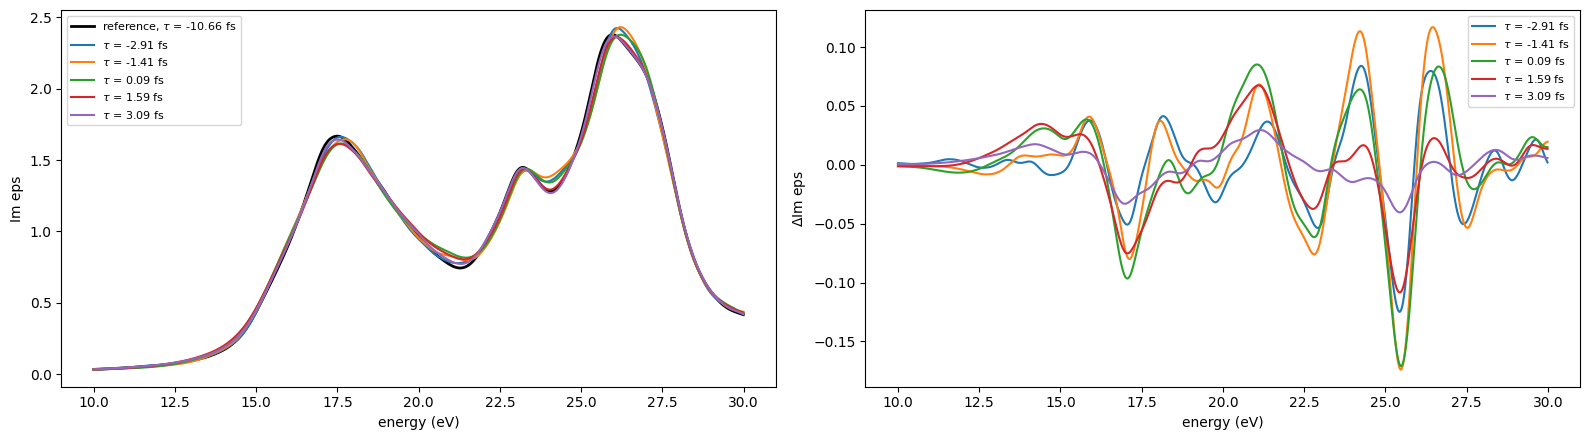

In [4]:
def plot_rt_spectra(runs, taus, quantity='Im eps', change=False, erange=(10,30), ax=None, **kw):
    # spectra (or their changes) at the delays closest to taus (fs)
    if ax is None: ax = plt.subplots(figsize=(10,4.5))[1]
    q = rt_quantity(runs,quantity,change=change,**kw)
    E = runs['energy']
    s = (E >= erange[0]) & (E <= erange[1])
    if not change: ax.plot(E[s],q[0,s],'k',lw=2,label=r'reference, $\tau$ = %.2f fs'%runs['tau'][0])
    for t in taus:
        i = np.argmin(np.abs(runs['tau']-t))
        ax.plot(E[s],q[i,s],label=r'$\tau$ = %.2f fs'%runs['tau'][i])
    ax.set_xlabel('energy (eV)')
    ax.set_ylabel(r'$\Delta$'+quantity if change else quantity)
    ax.legend(fontsize=8)
    return ax

fig,axes = plt.subplots(1,2,figsize=(16,4.5))
plot_rt_spectra(rt_ip,[-3,-1.5,0,1.5,3],ax=axes[0])
plot_rt_spectra(rt_ip,[-3,-1.5,0,1.5,3],change=True,ax=axes[1])
plt.tight_layout()

Maps of the change vs the delay (x) and the probe energy (y), as in the figures of D. Sangalli. With `tau_cut` the
left panel shows the reference and the spectrum at that delay and the right panel the change at that delay. Bottom:
$\Delta R/R$ at 72° (s polarization) in 20-50 eV with the color scale of his figure.

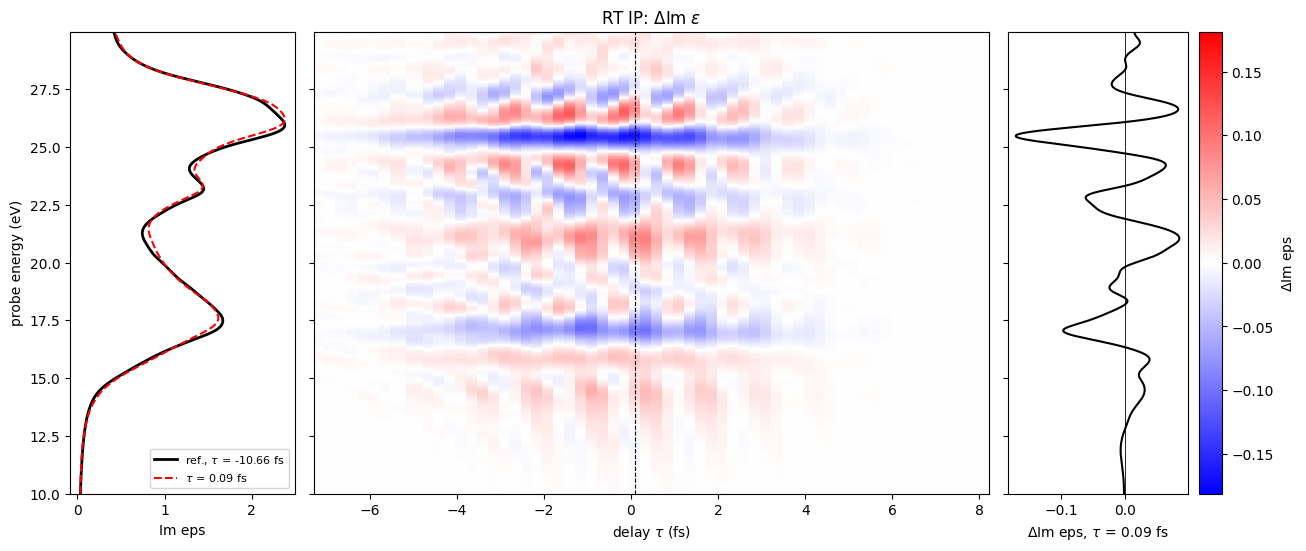

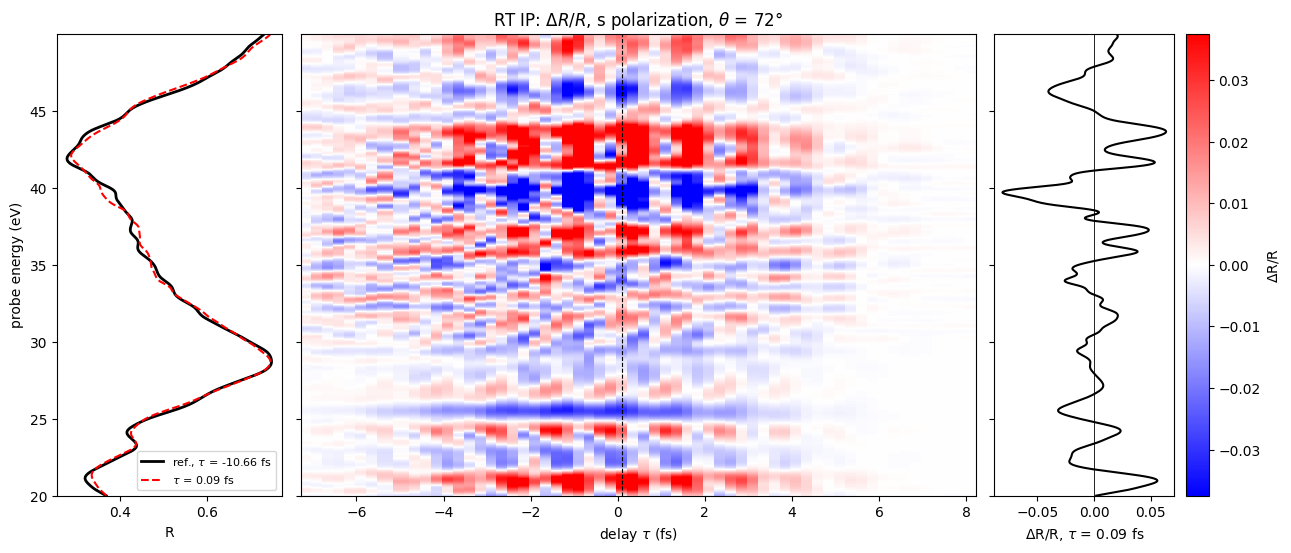

In [5]:
def plot_rt_map(runs, quantity='Im eps', relative=False, erange=(10,30), tau_cut=0., vmax=None, title=None, **kw):
    q = rt_quantity(runs,quantity,**kw)
    d = rt_quantity(runs,quantity,change=True,relative=relative,**kw)
    E, tau = runs['energy'], runs['tau']
    s = (E >= erange[0]) & (E <= erange[1])
    if vmax is None: vmax = np.abs(d[1:,s]).max()
    fig,axes = plt.subplots(1,3,figsize=(15,6),sharey=True,gridspec_kw=dict(width_ratios=[1,3,1],wspace=0.05))
    pc = axes[1].pcolormesh(tau[1:],E[s],d[1:,s].T,cmap='bwr',norm=TwoSlopeNorm(0,-vmax,vmax),shading='nearest')
    lab = r'$\Delta$%s/%s'%(quantity,quantity) if relative else r'$\Delta$%s'%quantity
    fig.colorbar(pc,ax=axes[2],label=lab)
    i = np.argmin(np.abs(tau-tau_cut))
    axes[1].axvline(tau[i],color='k',lw=0.8,ls='--')
    axes[1].set_xlabel(r'delay $\tau$ (fs)')
    axes[1].set_title(title if title else lab)
    axes[0].plot(q[0,s],E[s],'k',lw=2,label=r'ref., $\tau$ = %.2f fs'%tau[0])
    axes[0].plot(q[i,s],E[s],'r--',label=r'$\tau$ = %.2f fs'%tau[i])
    axes[0].set_xlabel(quantity)
    axes[0].set_ylabel('probe energy (eV)')
    axes[0].legend(fontsize=8)
    axes[2].plot(d[i,s],E[s],'k')
    axes[2].axvline(0,color='k',lw=0.6)
    axes[2].set_xlabel(r'%s, $\tau$ = %.2f fs'%(lab,tau[i]))
    return fig,axes

plot_rt_map(rt_ip,'Im eps',title=r'RT IP: $\Delta$Im $\epsilon$')
plot_rt_map(rt_ip,'R',relative=True,theta=72,pol='s',erange=(20,50),vmax=0.0375,
            title=r'RT IP: $\Delta R/R$, s polarization, $\theta$ = 72°');

## Equilibrium susceptibilities (yambo_nl, kx16)

Damping 0.3 eV in the dynamics plus an a posteriori Lorentzian broadening of 0.3 eV (`compute_Xn(broadening=0.3)`, on
the keys linear in the probe): total 0.6 eV, the smoothing of the RT spectra.

In [6]:
run_dir = 'kx16_nb100_NoTr_E100'
name_sine = 'pulse-E1_1e3-nlenrange_10.0-25.016-nlensteps_155-bands_3-6-damp_0.3-sin-nltime_100'
name_Pp = 'Pp-Ep_1e3-EP_1e6-PE_1.55-nlenrange_10.0-25.016-nlensteps_155-bands_3-6-damp_0.3-sin-nltime_100'
data_sine = P.YamboNLDBParser(os.path.join(run_dir,name_sine,'ndb.Nonlinear'),verbose=False)
data_Pp = P.YamboNLDBParser(os.path.join(run_dir,name_Pp,'ndb.Nonlinear'),verbose=False)
freq_mix = O.Xn_frequency_mixing(data_Pp,X_order=(1,2),verbose=False)
single = O.Xn_single_frequency(data_sine,X_order=3,verbose=False)
broad = 0.3                            # eV, a posteriori broadening: 0.3 + 0.3 = 0.6 eV, the smoothing of the RT spectra
# transient response from the chi: chi1 and the keys with the same broadening, keys (1,+-1) dropped (zero by symmetry)
tr = O.Transient_Response.from_Xn(freq_mix,single,broadening=broad,centrosymmetric=True)
freqs, chi1_sin, EP = tr.freqs, tr.chi1, tr.E0P   # probe grid (eV), chi1 of the sine runs, pump of the P&p run (au)

Probe frequencies: 155, from 10.000 to 24.919 eV, step 0.0969 eV
Pump of the frequency mixing runs: 1.5500 eV, amplitude 1.1936e-04 au
Orders of the terms included: [3] (centrosymmetric system)
Transient response defined from 13.100 to 21.819 eV (91 frequencies)


### Correction of the INVINT integrator and equilibrium check

The yambo_nl runs use the INVINT integrator with `NLstep` $dt$ = 0.01 fs, which has two effects (see the MPPI notes in
the CLAUDE.md of the project):

- in the static part of the dynamics a transition of energy $E$ evolves with $E_{eff} = (2\hbar/dt)\arctan(E\,dt/2\hbar)
  < E$, so the resonances of our $\chi$ are red shifted by $\simeq E^3dt^2/12\hbar^2$: 0.04, 0.06, 0.09, 0.13, 0.18 eV
  at 13, 15, 17, 19, 21 eV;
- the fields act with a delay $dt/2$, so every key is multiplied by $e^{i\omega dt/2}$, with $\omega$ the frequency of
  the output polarization: for the key $(1,m)$ at the probe frequency $\omega'$ the delays of the probe and of the pump
  give $e^{i(\omega'+m\omega_P)dt/2}$. The phase is 0.13 rad at 17 eV: it mixes Re $\chi$ into Im $\chi$ and moves the
  absorption edge.

The correction is $\chi_{corr}(\omega) = \chi(\omega_{eff})e^{-i\omega_{eff}dt/2}$ (linear interpolation on the grid),
applied to $\chi^{(1)}$ and to $\delta\chi(\omega)$ at the frequency of the spectrum (the same phase for the three
terms). All the spectra shown below are corrected. The RT runs use CRANKNIC with $dt$ = 3 as (shift $<$ 0.01 eV, phase 0.04 rad at 17 eV, neglected).

Equilibrium check: the earliest delay of the RT runs ($\tau$ = -10.66 fs, pump envelope $\sim10^{-5}$) is the
equilibrium spectrum of the RT setup (IP, bands 1-15), to be compared with $1+4\pi\chi^{(1)}$ of our runs (bands 3-6)
and with the IP spectra of the standard `yambo` optics (no time integration) on the same kx16 SAVE with the same
scissor, bands 3-6 and 1-15 (section "IP linear response with yambo optics" of `YamboNL_Analysis.ipynb`, damping
0.6 eV).

Im eps, yambo_nl        : shift of the edge (12-17.3 eV) towards RT -0.050 eV, towards optics 3-6 -0.009 eV
Im eps, optics 3-6      : shift of the edge (12-17.3 eV) towards RT -0.041 eV, towards optics 3-6  0.000 eV
Im eps, optics 1-15     : shift of the edge (12-17.3 eV) towards RT  0.026 eV, towards optics 3-6  0.067 eV


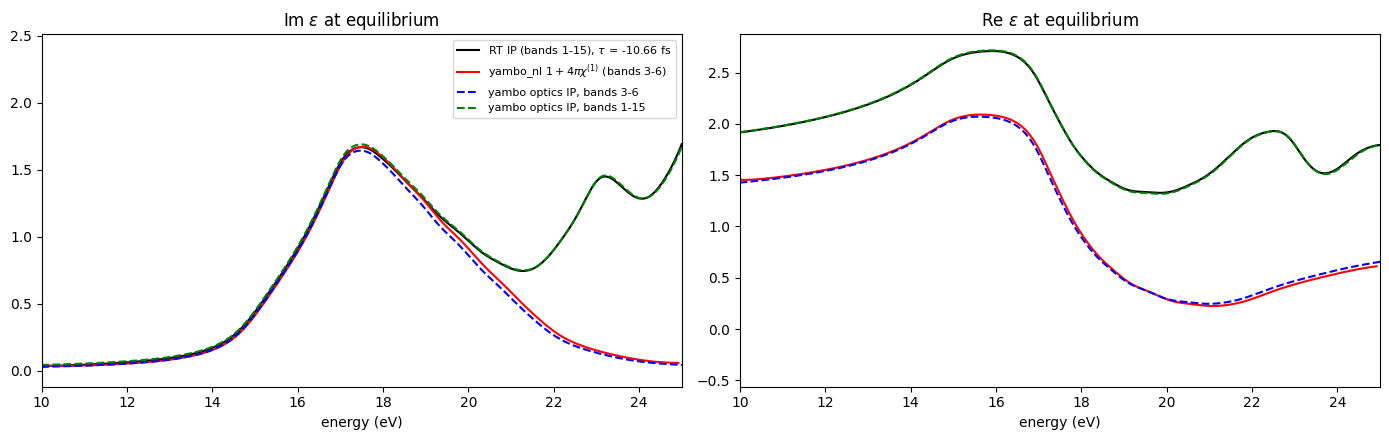

In [7]:
from scipy.optimize import minimize_scalar

def invint_correction(freqs, chi, dt=0.01):
    # removes the effects of the INVINT integrator with time step dt (fs) from chi (last axis on the grid freqs, eV, of
    # the output polarization): chi(w_eff) exp(-i w_eff dt/2), with w_eff = (2 hbar/dt) arctan(w dt/2 hbar)
    # (red shift of the resonances and delay dt/2 of the fields)
    hb = Const.Planck_reduced_ev_fs
    weff = 2*hb/dt*np.arctan(freqs*dt/(2*hb))
    chi = np.asarray(chi)*np.exp(-1j*freqs/hb*dt/2)
    out = [np.interp(weff,freqs,y.real)+1j*np.interp(weff,freqs,y.imag) for y in chi.reshape(-1,chi.shape[-1])]
    return np.array(out).reshape(chi.shape)

def best_shift(x, y, ref_x, ref_y, erange):
    # rigid shift (eV, > 0 to the right) of y(x) that minimizes the distance from ref_y(ref_x) in erange
    g = x[(x>=erange[0])&(x<=erange[1])]
    t = np.interp(g,ref_x,ref_y)
    return minimize_scalar(lambda a: np.sum((np.interp(g-a,x,y)-t)**2),bounds=(-1,1),method='bounded').x

def load_ip_optics(bands, folder='kx16_nb100_NoTr_E100'):
    # energy (eV) and eps of the IP yambo optics run with the given bands
    d = np.loadtxt(glob.glob(os.path.join(folder,'ip-optics-bands_%s-damp_0.6'%bands,'o-*.eps_q1_ip'))[0])
    return d[:,0], d[:,2]+1j*d[:,1]
ip_optics = {b: load_ip_optics(b) for b in ['3-6','1-15']}

eps_ref = rt_ip['eps'][0]
chi1_c = invint_correction(freqs,chi1_sin)   # corrected linear response of the yambo_nl runs
eps_nl = 1+4*np.pi*chi1_c

fig,axes = plt.subplots(1,2,figsize=(14,4.5))
for ax,part,lab in zip(axes,[np.imag,np.real],['Im','Re']):
    ax.plot(rt_ip['energy'],part(eps_ref),'k',label=r'RT IP (bands 1-15), $\tau$ = %.2f fs'%rt_ip['tau'][0])
    ax.plot(freqs,part(eps_nl),'r',label=r'yambo_nl $1+4\pi\chi^{(1)}$ (bands 3-6)')
    for (b,(x,e)),st in zip(ip_optics.items(),['b--','g--']):
        ax.plot(x,part(e),st,label='yambo optics IP, bands %s'%b)
    ax.set_xlim(10,25)
    ax.set_xlabel('energy (eV)')
    ax.set_title(r'%s $\epsilon$ at equilibrium'%lab)
axes[0].legend(fontsize=8)
plt.tight_layout()
curves = [('yambo_nl',freqs,eps_nl)] + [('optics %s'%b,x,e) for b,(x,e) in ip_optics.items()]
for lab,x,y in curves:
    print('Im eps, %-16s: shift of the edge (12-17.3 eV) towards RT %6.3f eV, towards optics 3-6 %6.3f eV'%(
          lab,best_shift(x,y.imag,rt_ip['energy'],eps_ref.imag,(12,17.3)),best_shift(x,y.imag,*ip_optics['3-6'][0:1],ip_optics['3-6'][1].imag,(12,17.3))))

## Transient absorption from the non-linear $\chi$

The two descriptions are linked by the following equation
\begin{eqnarray}
\chi^{neq,(1)}[E_P](\omega) &=& \chi^{(1)}(\omega;\omega) + \nonumber \\
&+& \left[ \chi^{(2)}(\omega;\omega_P,\omega-\omega_P)\frac{E_{p}(\omega-\omega_P)}{E_p(\omega)} + 
\chi^{(2)}(\omega;-\omega_P,\omega+\omega_P)\frac{E_{p}(\omega+\omega_P)}{E_p(\omega)}
\right]E_{P}(\omega_P)  + \nonumber \\ &+&\left[   
\chi^{(3)}(\omega;\omega_P,\omega_P,\omega-2\omega_P)\frac{E_{p}(\omega-2\omega_P)}{E_p(\omega)} + 
\chi^{(3)}(\omega;\omega_P,-\omega_P,\omega) + \right. \nonumber \\ &&\left.
\chi^{(3)}(\omega;-\omega_P,-\omega_P,\omega+2\omega_P)\frac{E_{p}(\omega+2\omega_P)}{E_p(\omega)}
\right]E^2_{P}(\omega_P)
\end{eqnarray}

### Formula used for $\delta\chi^{neq}$

The MPPI key `Xn_frequency_mixing(...).compute_Xn()[0][(1,m)]` at the probe frequency $\omega$ is the ratio between the
component of $P$ at $\omega+m\omega_P$ and the product $E_p(\omega)E_P(\pm\omega_P)^{|m|}$ of the field amplitudes, with
$E(t) = \sum_n E(\omega_n)e^{-i\omega_n t}$, $E(-\omega) = E(\omega)^*$, and $E(\omega) = (iE_0/2)e^{i\omega t_0}$ for a
sine field $E_0\sin(\omega(t-t_0))$ (Boyd, Sec. 1.3; the keys include the degeneracy factors, $\chi_{(1,\pm2)} = 3\chi^{(3)}$).

Only the third order terms are kept: the second order terms $\chi_{(1,\pm1)}$ vanish by symmetry in LiF (in our runs
they are an error of the k discretization, see `NL-Chi_Analysis.ipynb`). The change of the response at the frequency
$\omega$ of the transient spectrum is

$$
\delta\chi(\omega) = \chi_{(1,1,-1)}(\omega)|E_P(\omega_P)|^2
+ \chi_{(1,2)}(\omega-2\omega_P)\frac{E_p(\omega-2\omega_P)}{E_p(\omega)}E_P(\omega_P)^2
+ \chi_{(1,-2)}(\omega+2\omega_P)\frac{E_p(\omega+2\omega_P)}{E_p(\omega)}E_P(-\omega_P)^2 ,
\qquad \chi_{(1,1,-1)} = \frac{\chi_{(1,0)}-\chi^{(1)}}{E_{0P,run}^2/4}
$$

($E_{0P,run}$ is the pump amplitude of the yambo_nl run). It holds for a monochromatic pump. The fields of the RT runs:

- **probe**: delta kick at $t_p$, $E_p(\omega)\propto e^{i\omega t_p}$, so $E_p(\omega\mp2\omega_P)/E_p(\omega) =
  e^{\mp2i\omega_P t_p}$;
- **pump**: a pulse. For QSFIELD with phase 90° yambo (`RT_small_a`) sets the vector potential
  $A(t)\propto f(t)\cos(\omega_P(t-t_P))$, with the envelope $f(t) = e^{-(t-t_P)^2/2\sigma^2}$ centered at $t_P$, and
  $E = -\dot A$, i.e. $E_P(t) = -E_{0P}f(t)[\sin(\omega_P(t-t_P)) + (t-t_P)\cos(\omega_P(t-t_P))/\omega_P\sigma^2]$
  (checked in `RT_small_a.F` and `RT_Ext_fields.F` of Lumen). The second term, the derivative of the envelope, is
  $\sim$12% of the field at $|t-t_P|$ = 3 fs and acts on the phases of the $(1,\pm2)$ terms as a pump frequency larger by
  $\hbar/\omega_P\sigma^2\simeq$ 0.03 eV: we neglect it, $E_P(t) = -E_{0P}f(t)\sin(\omega_P(t-t_P))$.

**Quasi-monochromatic approximation.** The signal of the delta probe is built in a short time after $t_p$: the
smoothing of 0.6 eV damps the probe polarization in $\hbar/0.6$ eV $\simeq$ 1.1 fs, shorter than $\sigma$. In this
time the envelope is nearly constant, $f(t)\simeq f(t_p) = e^{-\tau^2/2\sigma^2}$ with the delay $\tau = t_p - t_P$, so
the pump acts on the probe response as a monochromatic sine field of amplitude $E_{0P}f(\tau)$ with phase reference
$t_P$. With the convention above its amplitude is $E_P(\omega_P) = -(iE_{0P}f(\tau)/2)\,e^{i\omega_P t_P}$, hence

$$
|E_P(\omega_P)|^2 = \frac{E_{0P}^2}{4}e^{-\tau^2/\sigma^2} \equiv |E_P(\tau)|^2, \qquad
E_P(\pm\omega_P)^2 = -|E_P(\tau)|^2\,e^{\pm2i\omega_P t_P} .
$$

The minus sign is the square of $i$, i.e. it comes from the sine shape of the pump (for a cosine pump it would be +);
the global sign of the field does not matter. Combining the phases of the probe and of the pump,
$e^{\mp2i\omega_P(t_p-t_P)} = e^{\mp2i\omega_P\tau}$:

$$
\delta\chi(\omega,\tau) = |E_P(\tau)|^2\left[\chi_{(1,1,-1)}(\omega) - \chi_{(1,2)}(\omega-2\omega_P)\,e^{-2i\omega_P\tau}
- \chi_{(1,-2)}(\omega+2\omega_P)\,e^{2i\omega_P\tau}\right]
$$

and $\Delta\epsilon(\omega,\tau) = 4\pi\,\delta\chi(\omega,\tau)$ is compared with $\epsilon(\omega,\tau)-\epsilon_{ref}(\omega)$
of the RT runs. The phases depend only on the delay: the term $\chi_{(1,1,-1)}$ does not oscillate with $\tau$, the
$(1,\pm2)$ terms oscillate with period $\pi/\omega_P$ = 1.33 fs.

The formula is implemented in the MPPI class `Transient_Response` (`O.Transient_Response.from_Xn(mix, single,
broadening, centrosymmetric=True)` builds $\chi_{(1,1,-1)}$ and the shifted keys from the runs, the method
`dchi(taus, E0P, pump='probe time', sigma, wP)` gives $\delta\chi(\omega,\tau)$ with $\sigma$ the width of the field
envelope $f$); the INVINT correction is applied here to its output.

### Frequency grids

The key $(1,m)$ computed at the probe frequency $\omega'$ of the runs is the response at $\omega'+m\omega_P$. In the
spectrum at the frequency $\omega$ the three terms are therefore read at $\omega' = \omega$ ($\chi_{(1,1,-1)}$),
$\omega-2\omega_P$ ($\chi_{(1,2)}$) and $\omega+2\omega_P$ ($\chi_{(1,-2)}$). Each key alone covers a shifted range of
output frequencies, but $\delta\chi(\omega)$ is defined only where all three terms are available:
$\omega\in[\omega'_{min}+2\omega_P,\ \omega'_{max}-2\omega_P]$ = 13.10-21.82 eV for the probe window 10.000-24.919 eV.
The probe step of the runs is $\omega_P/16$ = 0.096875 eV, so $2\omega_P$ = 32 steps and the shifted frequencies are
exactly on the grid (an index shift, no interpolation). A wider range of $\omega$ needs a wider probe window. `Transient_Response` checks that the step divides
$2\omega_P$ and gives the output grid `tr.w`.

Other ingredients of the comparison with the RT runs:

- **pump frequency**: 1.55 eV in the yambo_nl runs, 1.56 eV in the RT runs. The keys are read with the shift $2\omega_P$
  of the runs (3.10 instead of 3.12 eV, negligible with a broadening of 0.6 eV), the phases $e^{\mp2i\omega_P\tau}$ use
  the RT pump frequency (0.02 eV give 0.4 rad at 7 fs; argument `wP` of `tr.dchi`);
- **pump amplitude**: yambo intensities are in kW/cm$^2$ (the `kWLm2` of the inputs; $E_0 = \sqrt{4\pi I/c}$ in atomic
  units, 1e6 kW/cm$^2$ give the $E_0$ = 1.194e-4 au of our runs). The RT pump, 6e9 kW/cm$^2$, has $E_{0P}$ = 9.25e-3 au:
  intensity 6000 times the one of our runs, far beyond the range of the pump intensity test (fifth order corrections
  $\propto I_P$, 1-2% of the cubic terms at 1.6e7 kW/cm$^2$), so higher orders can be relevant in the RT runs;
- **bands**: 3-6 in our runs, 1-15 in the RT IP runs: transitions to the bands above 6 (from $\sim$19-20 eV) are missing
  in our $\chi$.

In [8]:
# pump of the RT runs: amplitude from the ratio of the intensities (kW/cm^2) w.r.t. the yambo_nl run (1e6 kW/cm^2)
pump_rt = rt_ip['pump']
E0P_rt = EP*np.sqrt(pump_rt['intensity']/1e6)
# envelope at the probe time; the phases use the RT pump frequency, the shifted grids the one of the yambo_nl runs
w, dchi = tr.dchi(rt_ip['tau'],E0P_rt,pump='probe time',sigma=pump_rt['sigma'],wP=pump_rt['freq'])
deps_chi = 4*np.pi*invint_correction(w,dchi)   # INVINT correction at the frequency of the spectrum
deps_rt = np.array([np.interp(w,rt_ip['energy'],d.real)+1j*np.interp(w,rt_ip['energy'],d.imag)
                    for d in rt_ip['eps']-rt_ip['eps'][0]])
print('omega %.3f-%.3f eV (%d points), E0P of the RT pump %.3e au (%.0f times the yambo_nl one)'%(w[0],w[-1],len(w),E0P_rt,E0P_rt/EP))

omega 13.100-21.819 eV (91 points), E0P of the RT pump 9.246e-03 au (77 times the yambo_nl one)


Comparison at three delays around the pump maximum (black: RT, red: from the $\chi$) and maps of $\Delta$Im $\epsilon$
vs the delay (same color scale).

RT         max |Delta eps| (all delays): 13.1-17.5 eV 0.107, 17.5-21.8 eV 0.099
chi3       max |Delta eps| (all delays): 13.1-17.5 eV 0.155, 17.5-21.8 eV 0.091
           rel. rms distance from RT in 13.6-17.5 eV (all delays): 0.677


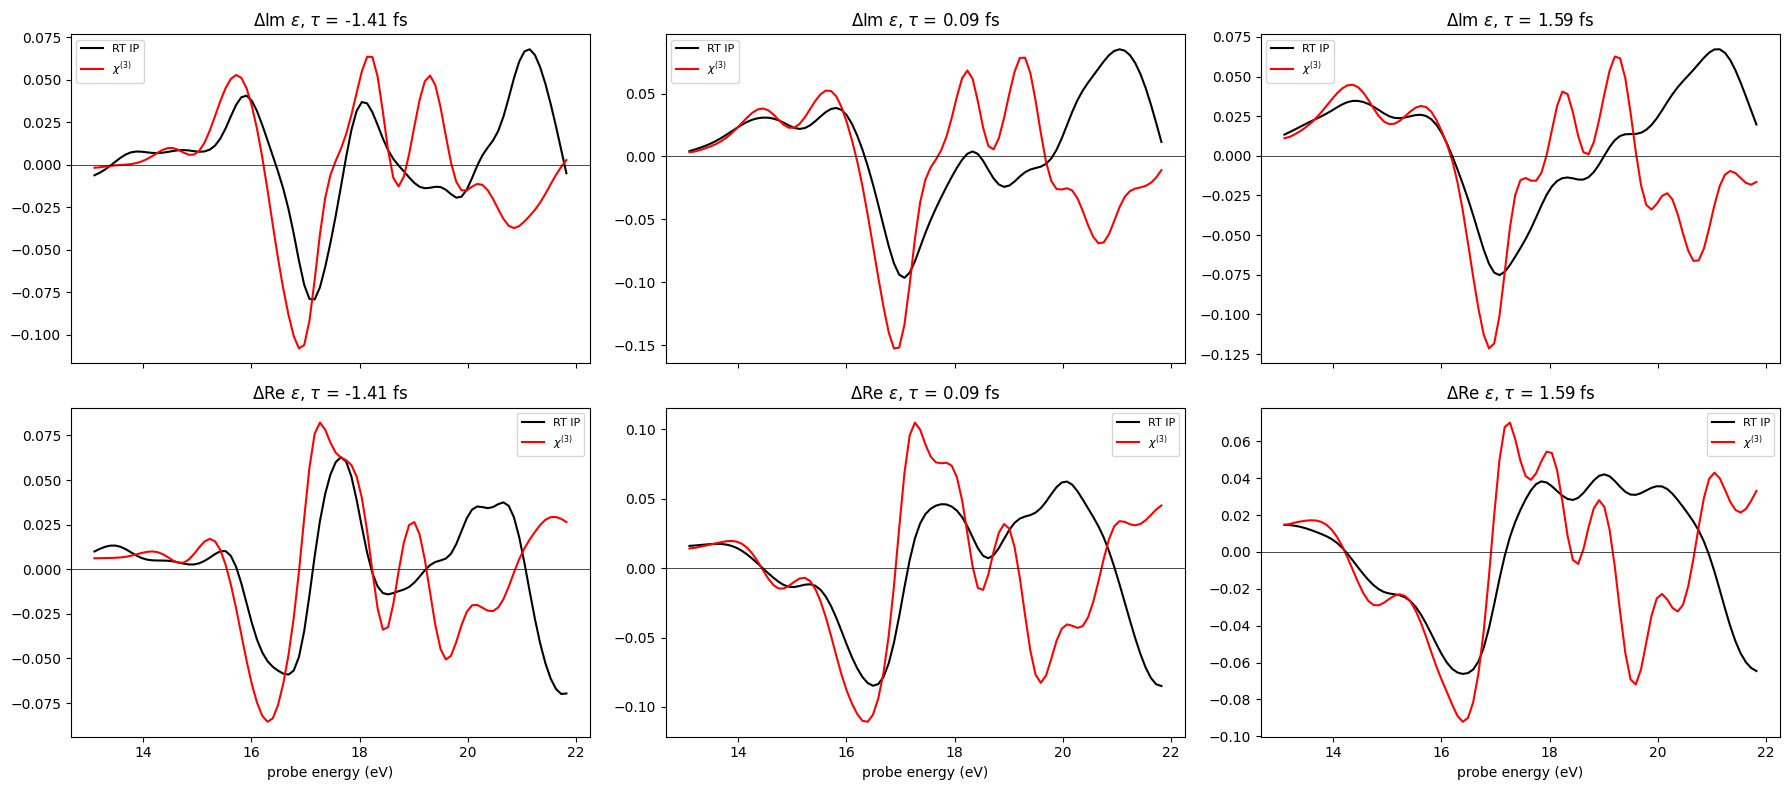

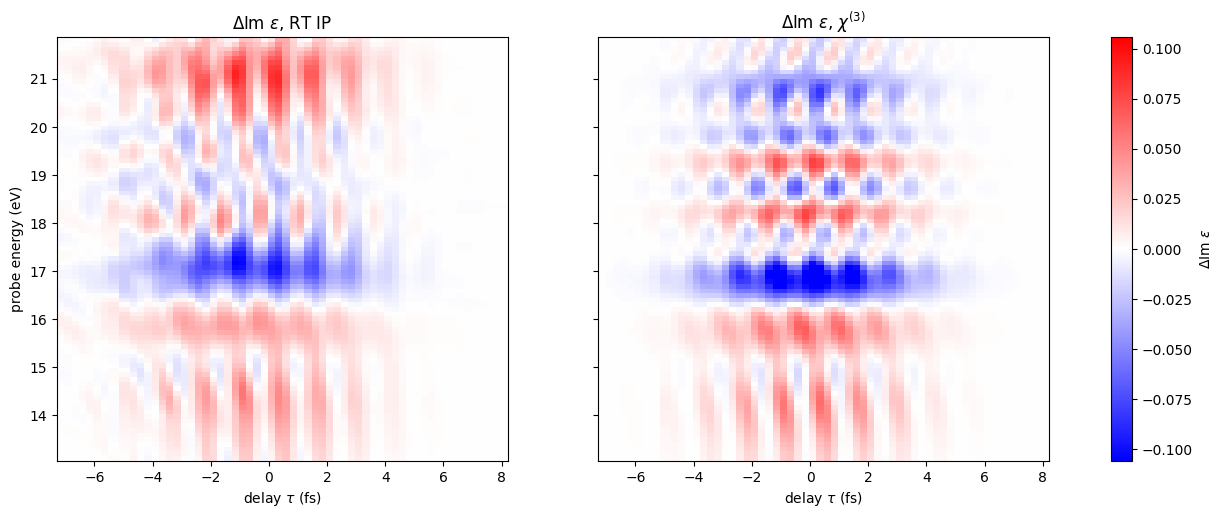

In [9]:
taus_cmp = [-1.4,0.1,1.6]
fig,axes = plt.subplots(2,len(taus_cmp),figsize=(18,8),sharex=True)
for k,t in enumerate(taus_cmp):
    i = np.argmin(np.abs(rt_ip['tau']-t))
    for row,(part,lab) in enumerate([(np.imag,'Im'),(np.real,'Re')]):
        ax = axes[row,k]
        ax.plot(w,part(deps_rt[i]),'k',label='RT IP')
        ax.plot(w,part(deps_chi[i]),'r',label=r'$\chi^{(3)}$')
        ax.axhline(0,color='k',lw=0.5)
        ax.set_title(r'$\Delta$%s $\epsilon$, $\tau$ = %.2f fs'%(lab,rt_ip['tau'][i]))
        ax.legend(fontsize=8)
for ax in axes[-1]: ax.set_xlabel('probe energy (eV)')
plt.tight_layout()

it = np.arange(1,len(rt_ip['tau']))
vmax = np.abs(deps_rt[it].imag).max()
fig,axes = plt.subplots(1,2,figsize=(16,5.5),sharey=True)
for ax,d,lab in zip(axes,[deps_rt,deps_chi],['RT IP',r'$\chi^{(3)}$']):
    pc = ax.pcolormesh(rt_ip['tau'][it],w,d[it].imag.T,cmap='bwr',norm=TwoSlopeNorm(0,-vmax,vmax),shading='nearest')
    ax.set_title(r'$\Delta$Im $\epsilon$, %s'%lab)
    ax.set_xlabel(r'delay $\tau$ (fs)')
axes[0].set_ylabel('probe energy (eV)')
fig.colorbar(pc,ax=axes,label=r'$\Delta$Im $\epsilon$')

m = w < 17.5
sel = (w >= 13.6) & (w <= 17.5)
for lab,d in [('RT',deps_rt),('chi3',deps_chi)]:
    print('%-10s max |Delta eps| (all delays): 13.1-17.5 eV %.3f, 17.5-21.8 eV %.3f'%(lab,np.abs(d[it][:,m]).max(),np.abs(d[it][:,~m]).max()))
    if lab != 'RT':
        print('%-10s rel. rms distance from RT in 13.6-17.5 eV (all delays): %.3f'%('',
              np.linalg.norm(d[it][:,sel]-deps_rt[it][:,sel])/np.linalg.norm(deps_rt[it][:,sel])))

**Comparison RT IP vs $\chi^{(3)}$ (no free parameters).** Below $\sim$17.5 eV the reconstruction from the $\chi$
reproduces the RT spectra: the bleach at 17 eV, the positive band at 14-16 eV, the oscillations with period
$\pi/\omega_P$ = 1.33 fs in phase with the RT ones and the decay with the pump envelope. The bleach at 17 eV is $\sim$1.5
times larger than in the RT runs (maxima printed above). Above 17.5 eV the shapes differ.

**Equilibrium.** The INVINT correction (the phase $\omega dt/2$ is the larger effect) brings the yambo_nl $\chi^{(1)}$ onto
the `yambo` optics spectrum with the same bands (edge within 0.01 eV, 2% on $\epsilon$; 0.8% for the delta run), and the
optics spectrum with the bands 1-15 coincides with the RT reference (edge within 0.03 eV: yambo 5.3 and Lumen agree).
Without the correction the edge was 0.26 eV below the RT one. The bands 7-15 move the edge by only 0.07 eV, but they add
the absorption above 19 eV and $\sim$0.5 to Re $\epsilon$.

**Residual shift.** A rigid shift of the reconstructed $\Delta\epsilon$ to the right still improves the agreement in
13.6-17.5 eV (best shift 0.22 eV, rel. rms distance 0.68 $\to$ 0.44; before the correction 0.34 eV from 0.93). Unlike
the equilibrium one it depends on the pump envelope: 0.15-0.27 eV for $e^{-\tau^2/\sigma^2}>0.5$, 0.04-0.14 eV in the tail
after the pump, and near the maximum the RT signal is smaller than the $\chi^{(3)}$ one (ratio 0.6-0.85). This is what one
expects beyond third order: a pump induced shift $\Delta$ of the edge gives
$\epsilon(\omega-\Delta)-\epsilon(\omega)\simeq-\Delta\,\epsilon'(\omega-\Delta/2)$, the perturbative $-\Delta\epsilon'(\omega)$
moved by $\Delta/2$ and reduced when $\Delta$ is comparable with the 0.6 eV broadening; the RT pump intensity is 1500 times
the highest one of our perturbative tests (4e6 kW/cm$^2$). Checked with our RT runs at lower pump intensity (next section). Still
open: the bands above 6 in the cubic terms and their k convergence (16-21 eV).

## Our RT runs with the bands 3-6

RT pump-probe runs with `yambo_nl` and the same setup of the IP runs of D. Sangalli (section "RT pump-probe runs with the
setup of D. Sangalli" of `YamboNL_Analysis.ipynb`, folder `kx16_nb100_NoTr_E100/rt-ip-*`): CRANKNIC 3 as, 40 fs, no
damping, delta probe at $t_p$, QSFIELD PHPI90 5SIGMA pump at 1.56 eV ($t_P$ = 15.909 fs). For each run
$\Delta\epsilon = \epsilon[P_{Pp}-P_P] - \epsilon_{eq}$, with the pump-only run of the same pump and the probe-only run
as reference (`Linear_Response`, Lorentzian smoothing 0.6 eV as in ypp). The setup is the one of D. Sangalli: our run
with the bands 1-15 and the pump 6e9 kW/cm$^2$ at $t_p$ = 16 fs coincides with his one ($3\cdot10^{-7}$ on $\epsilon$),
and the probe-only spectra coincide with the `yambo` optics ones (0.8%).

Here only the runs with the bands 3-6, the same as the $\chi$: pump 6e9 (the one of D. Sangalli) and 6e7 kW/cm$^2$,
probe at $t_p$ = 13, 14.5, 16, 17.5, 19 fs ($\tau$ = -2.91, -1.41, 0.09, 1.59, 3.09 fs). Distances in
13.6-17.5 eV: relative rms, ratio of the maxima ($\chi^{(3)}$/RT) and best rigid shift of the $\chi^{(3)}$ spectrum
(> 0 to the right).

In [10]:
nl_rt_dir = 'kx16_nb100_NoTr_E100'
t_probes_nl = [13.0,14.5,16.0,17.5,19.0]
I_nl = [6e9,6e7]

def rt_id(bands, pump_int=None, t_probe=None, neg=False):
    # run id of the RT runs of YamboNL_Analysis.ipynb (bands as a string, e.g. '3-6'; neg: pump along -x)
    idd = 'rt-ip-bands_%s'%bands
    if pump_int is not None: idd += '-EP_%s'%('%.0e'%pump_int).replace('e+0','e') + ('-neg' if neg else '')
    if t_probe is not None: idd += '-tp_%.2f'%t_probe
    return idd + '-' + {(True,True):'Pp',(True,False):'P',(False,True):'p'}[(pump_int is not None,t_probe is not None)]

def load_nl(path):
    return P.YamboNLDBParser(os.path.join(path,'ndb.Nonlinear'),verbose=False)

def nl_eps(run, ref=None, eta=0.6):
    # energy (eV) and eps along x from the delta probe of the run, minus the polarization of ref (pump only)
    return O.Linear_Response(np.array(run.IO_TIME_points),run.Polarization[0],run.Efield[0],
                             pol_ref=None if ref is None else ref.Polarization[0],eta=eta)

def nl_delay(run):
    # tau = t_p - t_P (fs), t_P = maximum of the QSFIELD 5SIGMA pump (as in yambo RT_small_a)
    pump = run.Efield2[0]
    wP, sigma = pump['freq_range'][0], pump['damping']/(2*np.sqrt(2*np.log(2)))     # au, damping = FWHM
    t_P = pump['initial_time'] + np.pi/wP*np.rint(wP/np.pi*5*sigma)
    return (run.Efield[0]['initial_time']-t_P)/Const.FsToAu

on_w = lambda x, y: np.interp(w,x,y.real)+1j*np.interp(w,x,y.imag)      # complex spectrum on the grid w of the transient response

def best_shift_c(y, ref, erange):
    # rigid shift (eV, > 0 to the right) of the complex spectrum y(w) that minimizes the distance from ref(w) in erange
    s = (w>=erange[0])&(w<=erange[1])
    return minimize_scalar(lambda a: np.sum(np.abs(np.interp(w[s]-a,w,y.real)+1j*np.interp(w[s]-a,w,y.imag)-ref[s])**2),
                           bounds=(-1,1),method='bounded').x

def compare(y, ref, erange=(13.6,17.5)):
    # rel. rms distance, ratio of the maxima and best shift of y w.r.t. ref in erange
    s = (w>=erange[0])&(w<=erange[1])
    return (np.linalg.norm(y[s]-ref[s])/np.linalg.norm(ref[s]), np.abs(y[s]).max()/np.abs(ref[s]).max(),
            best_shift_c(y,ref,erange))

# Delta eps of the runs (bands 3-6) and chi3 reconstruction at their delays
en_nl, eps_eq_nl = nl_eps(load_nl(os.path.join(nl_rt_dir,rt_id('3-6',None,10.0))))
deps_nl, tau_nl = {}, {}
for I,neg in [(6e9,False),(6e9,True),(6e7,False),(6e7,True)]:
    ref = load_nl(os.path.join(nl_rt_dir,rt_id('3-6',I,neg=neg)))
    for tp in t_probes_nl:
        run = load_nl(os.path.join(nl_rt_dir,rt_id('3-6',I,tp,neg)))
        deps_nl[(I,neg,tp)], tau_nl[tp] = on_w(en_nl,nl_eps(run,ref)[1]-eps_eq_nl), nl_delay(run)
_, dchi_nl = tr.dchi([tau_nl[tp] for tp in t_probes_nl],E0P_rt,pump='probe time',sigma=pump_rt['sigma'],
                    wP=pump_rt['freq'])
deps_chi_nl = dict(zip(t_probes_nl,4*np.pi*invint_correction(w,dchi_nl)))
for tp in t_probes_nl:
    print('tau %5.2f fs: chi3 vs RT 6e9: rms %.2f, ratio %.2f, shift %+.2f eV'%(tau_nl[tp],*compare(deps_chi_nl[tp],deps_nl[(6e9,False,tp)])))

tau -2.91 fs: chi3 vs RT 6e9: rms 0.52, ratio 0.85, shift +0.19 eV
tau -1.41 fs: chi3 vs RT 6e9: rms 0.75, ratio 1.21, shift +0.24 eV
tau  0.09 fs: chi3 vs RT 6e9: rms 0.69, ratio 1.62, shift +0.16 eV
tau  1.59 fs: chi3 vs RT 6e9: rms 0.72, ratio 1.80, shift +0.22 eV
tau  3.09 fs: chi3 vs RT 6e9: rms 0.70, ratio 1.69, shift +0.22 eV


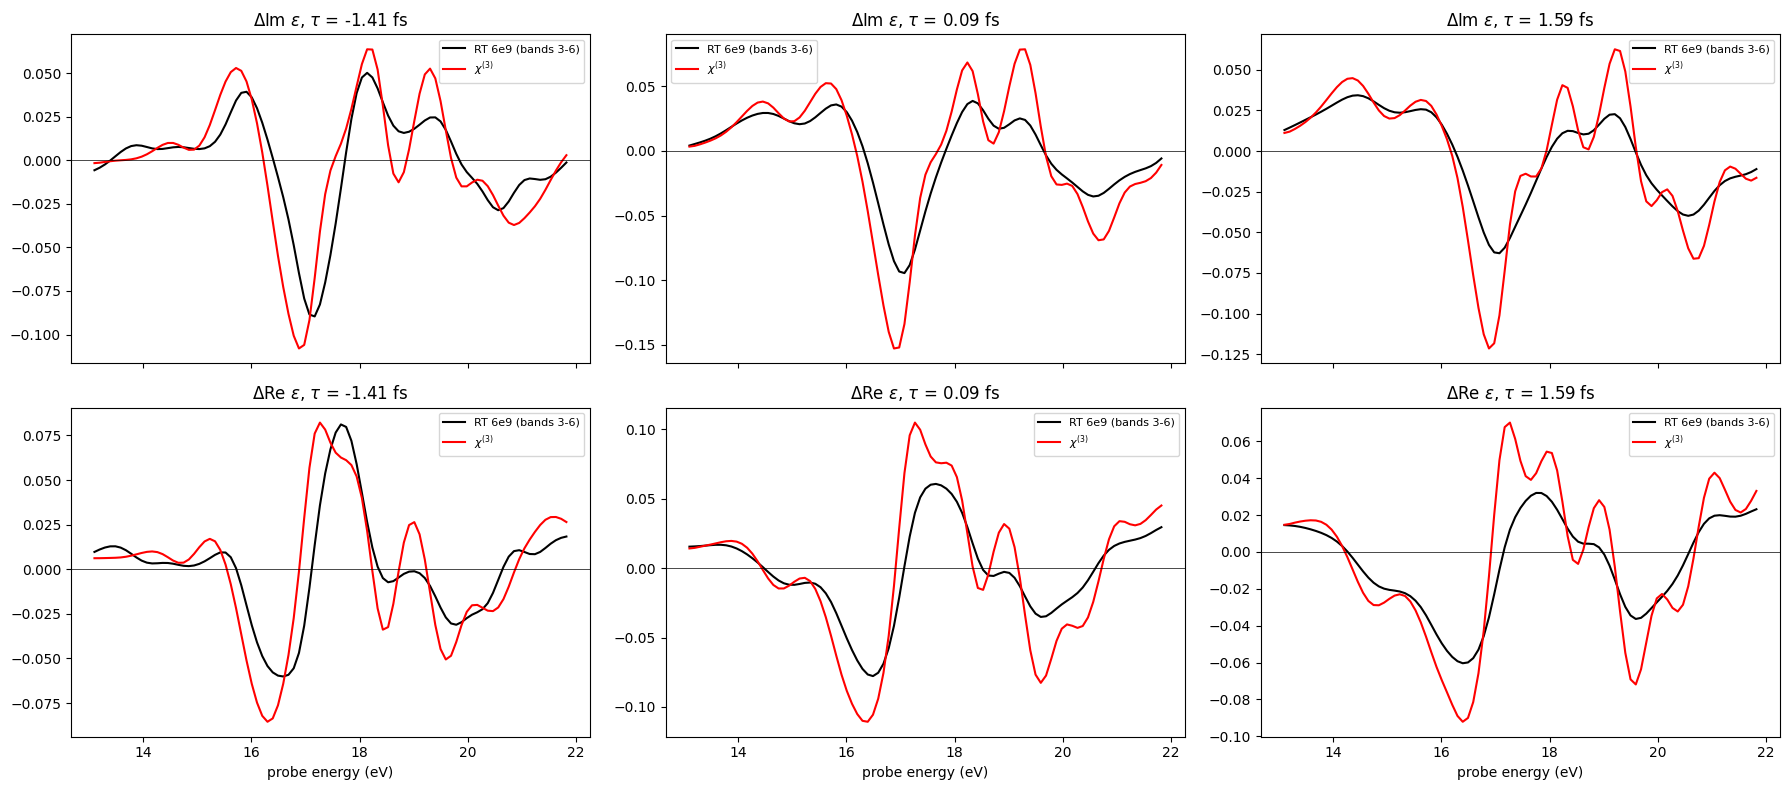

In [11]:
tps_cmp = [14.5,16.0,17.5]
fig,axes = plt.subplots(2,len(tps_cmp),figsize=(18,8),sharex=True)
for k,tp in enumerate(tps_cmp):
    for row,(part,lab) in enumerate([(np.imag,'Im'),(np.real,'Re')]):
        ax = axes[row,k]
        ax.plot(w,part(deps_nl[(6e9,False,tp)]),'k',label='RT 6e9 (bands 3-6)')
        ax.plot(w,part(deps_chi_nl[tp]),'r',label=r'$\chi^{(3)}$')
        ax.axhline(0,color='k',lw=0.5)
        ax.set_title(r'$\Delta$%s $\epsilon$, $\tau$ = %.2f fs'%(lab,tau_nl[tp]))
        ax.legend(fontsize=8)
for ax in axes[-1]: ax.set_xlabel('probe energy (eV)')
plt.tight_layout()

With the same bands of the $\chi$ the picture is the same as with the RT runs of D. Sangalli (bands 1-15): the
$\chi^{(3)}$ reproduces the structures of the RT spectra, but it is shifted by $\sim$0.2 eV to the left, its bleach at
17 eV is larger (ratio of the maxima 1.2-1.8 from $\tau$ = -1.4 fs on) and above 18 eV it has sharper structures. So the
bands are not the origin of these differences (bands 1-15 and 3-6 also give the same RT $\Delta\epsilon$ below 17.5 eV,
rel. rms 0.03-0.15). The other candidate is the pump intensity: 6e9 kW/cm$^2$ may be beyond the third order.

### Pump intensity: third order RT response

At 6e7 kW/cm$^2$ the orders above the third are negligible, but the RT $\Delta\epsilon$ rescaled by $6\cdot10^9/I_P$ does not
reproduce the $\chi^{(3)}$ either: it also contains the spurious second order term, linear in $E_P$ (the
$\chi_{(1,\pm1)}$ of the k discretization, `NL-Chi_Analysis.ipynb`), which is comparable with the third order one below
$\sim$3e7 kW/cm$^2$ on kx16. It is removed with the runs with the pump reversed (along $-x$, `study_rt_neg` of
`YamboNL_Analysis.ipynb`): the orders odd in $E_P$ change sign, the even ones do not, so the even part
$[\Delta\epsilon(+E_P)+\Delta\epsilon(-E_P)]/2$ is the third order RT response (the fifth order is $\sim10^{-3}$ of it at
6e7), and the odd part $[\Delta\epsilon(+E_P)-\Delta\epsilon(-E_P)]/2$ is the spurious second order term. Both are
rescaled to 6e9. The difference between the RT at 6e9 and the even part measures the orders above the third at 6e9 (the spurious term is small
at 6e9, see below).

tau -2.91 fs | chi3 vs RT 6e7 x 100: rms 1.13 | max|odd|/max|even| 1.56 | chi3 vs even part: rms 0.34, ratio 0.69, shift +0.04 eV | RT 6e9 vs even part: rms 0.43
tau -1.41 fs | chi3 vs RT 6e7 x 100: rms 0.59 | max|odd|/max|even| 0.96 | chi3 vs even part: rms 0.17, ratio 0.95, shift +0.04 eV | RT 6e9 vs even part: rms 0.51
tau  0.09 fs | chi3 vs RT 6e7 x 100: rms 0.68 | max|odd|/max|even| 0.74 | chi3 vs even part: rms 0.23, ratio 1.20, shift +0.06 eV | RT 6e9 vs even part: rms 0.33
tau  1.59 fs | chi3 vs RT 6e7 x 100: rms 0.74 | max|odd|/max|even| 0.75 | chi3 vs even part: rms 0.41, ratio 1.44, shift +0.12 eV | RT 6e9 vs even part: rms 0.21
tau  3.09 fs | chi3 vs RT 6e7 x 100: rms 0.66 | max|odd|/max|even| 1.00 | chi3 vs even part: rms 0.65, ratio 1.70, shift +0.14 eV | RT 6e9 vs even part: rms 0.10


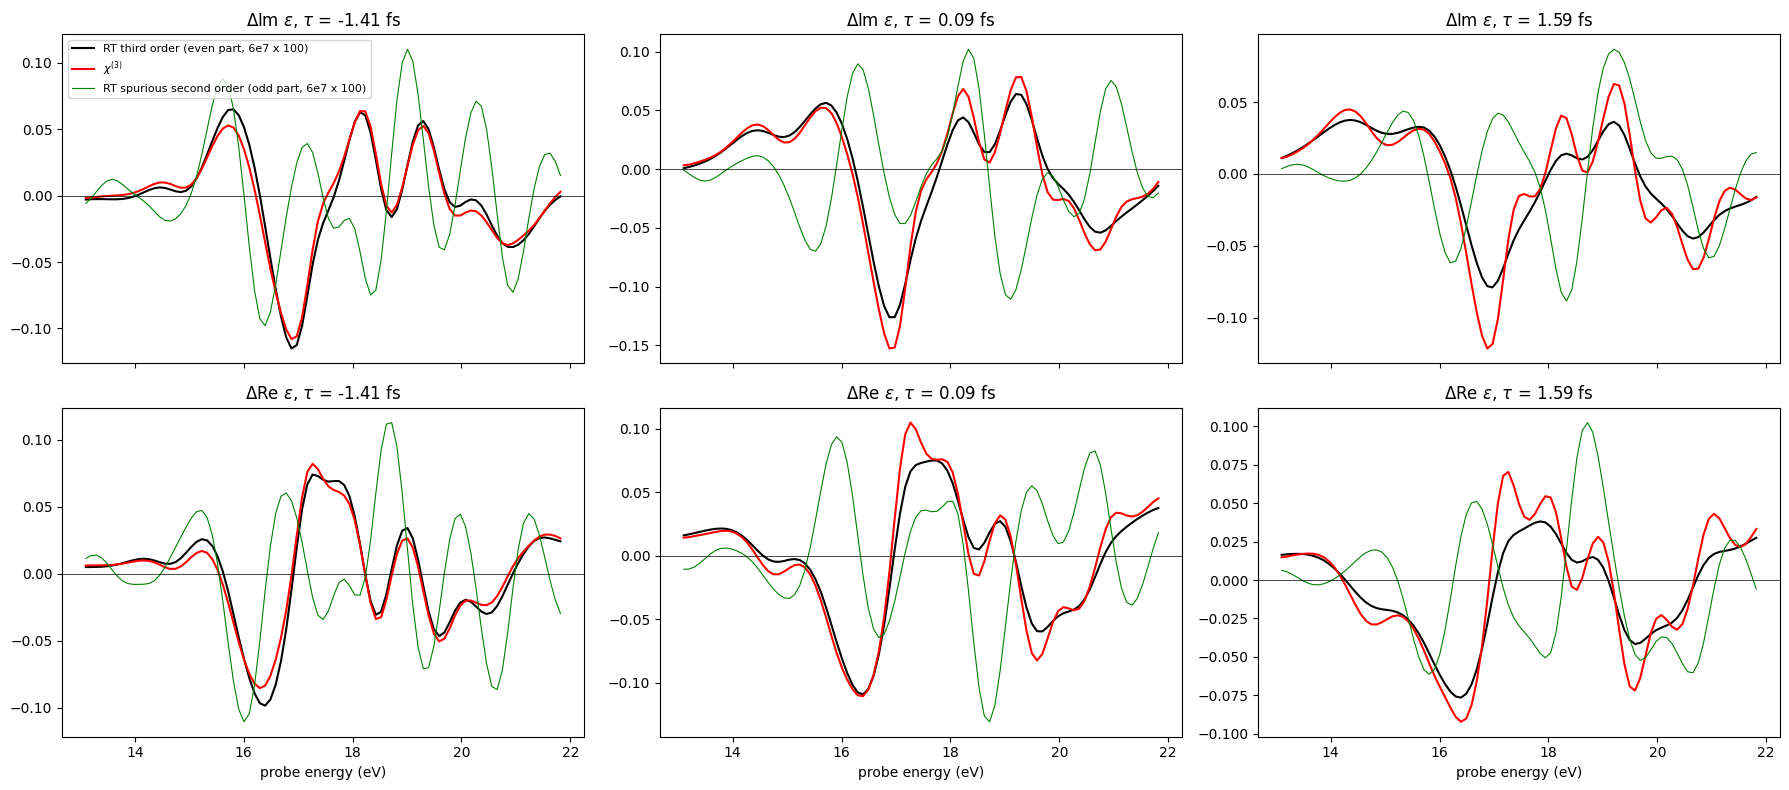

In [12]:
even_nl, odd_nl = {}, {}
s = (w>=13.6)&(w<=17.5)
for tp in t_probes_nl:
    dp, dm = deps_nl[(6e7,False,tp)], deps_nl[(6e7,True,tp)]
    even_nl[tp], odd_nl[tp] = (dp+dm)/2*6e9/6e7, (dp-dm)/2*6e9/6e7
    print('tau %5.2f fs | chi3 vs RT 6e7 x 100: rms %.2f | max|odd|/max|even| %.2f | chi3 vs even part: rms %.2f, ratio %.2f, shift %+.2f eV | RT 6e9 vs even part: rms %.2f'%(
          tau_nl[tp],compare(deps_chi_nl[tp],dp*6e9/6e7)[0],np.abs(odd_nl[tp][s]).max()/np.abs(even_nl[tp][s]).max(),
          *compare(deps_chi_nl[tp],even_nl[tp]),compare(deps_nl[(6e9,False,tp)],even_nl[tp])[0]))

fig,axes = plt.subplots(2,len(tps_cmp),figsize=(18,8),sharex=True)
for k,tp in enumerate(tps_cmp):
    for row,(part,lab) in enumerate([(np.imag,'Im'),(np.real,'Re')]):
        ax = axes[row,k]
        ax.plot(w,part(even_nl[tp]),'k',label='RT third order (even part, 6e7 x 100)')
        ax.plot(w,part(deps_chi_nl[tp]),'r',label=r'$\chi^{(3)}$')
        ax.plot(w,part(odd_nl[tp]),'g',lw=0.8,label='RT spurious second order (odd part, 6e7 x 100)')
        ax.axhline(0,color='k',lw=0.5)
        ax.set_title(r'$\Delta$%s $\epsilon$, $\tau$ = %.2f fs'%(lab,tau_nl[tp]))
axes[0,0].legend(fontsize=8)
for ax in axes[-1]: ax.set_xlabel('probe energy (eV)')
plt.tight_layout()

**Results.**

- At 6e7 the odd part (spurious second order) is as large as the even one (ratio of the maxima 0.7-1.6): the rescaled
  RT $\Delta\epsilon$ at 6e7 alone is not the third order response.
- The $\chi^{(3)}$ reproduces the third order RT response (even part) with **no shift** ($\le$ 0.06 eV near the pump
  maximum, $\le$ 0.14 eV elsewhere) and the right shape over the whole window 13-22 eV: rel. rms 0.17 and 0.23, ratio of
  the maxima 0.95 and 1.20 at $\tau$ = -1.41 and 0.09 fs. The yambo_nl $\chi^{(3)}$ (after the INVINT correction) and the
  RT third order response agree.
- Up to the pump maximum the RT at 6e9 differs from the third order one (rel. rms 0.33-0.51 for $\tau \le$ 0.1 fs): there
  the shift of $\sim$0.2 eV and the smaller bleach of the RT runs of D. Sangalli come from the orders above the third.
  After the maximum the RT at 6e9 is close to the third order one (rel. rms 0.21 and 0.10 at +1.6 and +3.1 fs), and the
  differences with the $\chi^{(3)}$ (also a shift of 0.12-0.14 eV) come from the formula (next point).
- Away from the pump maximum the size differs in a systematic way: $\chi^{(3)}$/RT = 0.69 at $\tau$ = -2.9 fs, 1.44 and
  1.70 at +1.6 and +3.1 fs, and after the maximum the $\chi^{(3)}$ has sharper structures in 17-21 eV. This is the
  approximation of the formula, which takes the pump envelope at the probe time: the probe polarization decays in
  $\hbar/0.6$ eV $\approx$ 1.1 fs while the envelope changes on $\sigma$ = 3.2 fs, so it feels a stronger pump before the
  maximum and a weaker one after it. A formula with the time dependence of the envelope is needed away from the maximum (section "Time dependence of the pump envelope").

#### High pump intensity: orders above the third

At 6e7 kW/cm$^2$ the even part removes the spurious term and is the third order response. At the pump of D. Sangalli
(6e9 kW/cm$^2$) removing the spurious term is not enough: the RT response also contains the orders above the third,
i.e. non perturbative terms beyond $\chi^{(3)}$. Same decomposition at 6e9 with the pump reversed (`study_rt_neg`): the
even part contains the third order and the orders above it, the odd part the spurious term (and the fourth order).
The spurious term grows as $E_P$, the third order as $E_P^2$: from 6e7 to 6e9 their ratio decreases by 10. The even part
at 6e9 compared with the third order response (even part at 6e7 $\times$ 100) shows the orders above the third.

6e9, 13.6-21.3 eV | max|odd|/max|even| | odd 6e9 / odd 6e7 x 10 (linear) | even 6e9 vs third order: rms, ratio, shift (eV) | RT 6e9 vs even 6e9: rms
tau -2.91 fs | 0.23 | 1.19 | 0.61 / 0.82 / -0.13 | 0.23
tau -1.41 fs | 0.08 | 0.63 | 0.49 / 0.77 / -0.13 | 0.11
tau  0.09 fs | 0.06 | 0.40 | 0.38 / 0.74 / -0.07 | 0.07
tau  1.59 fs | 0.08 | 0.52 | 0.25 / 0.82 / -0.01 | 0.07
tau  3.09 fs | 0.13 | 0.73 | 0.09 / 0.94 / -0.01 | 0.13


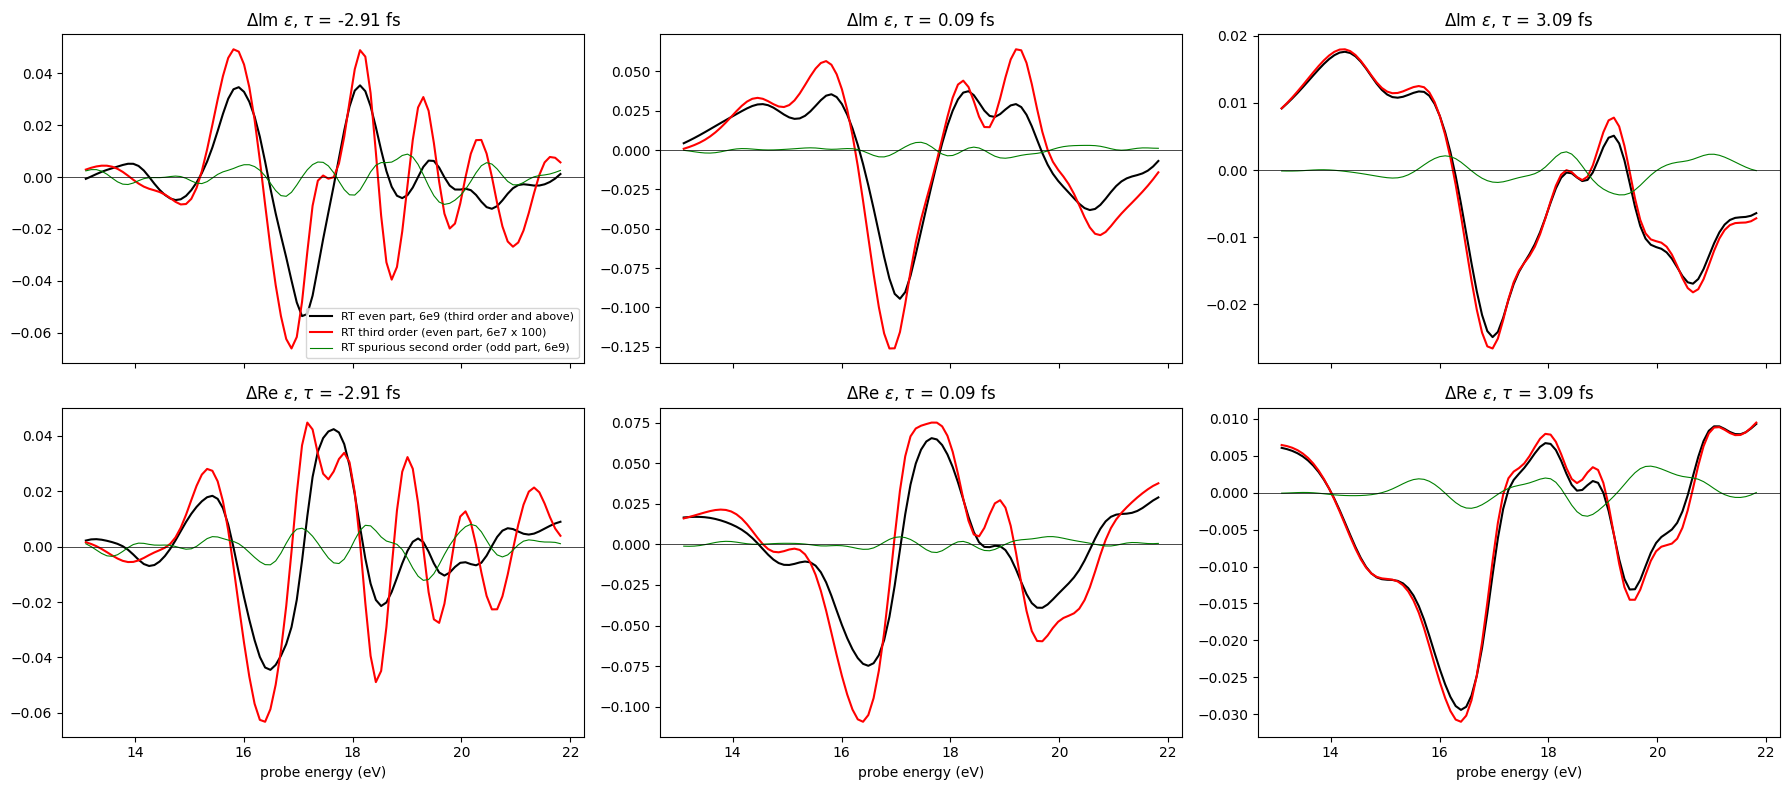

In [13]:
even_hi, odd_hi = {}, {}
s = (w>=13.6)&(w<=21.3)
print('6e9, 13.6-21.3 eV | max|odd|/max|even| | odd 6e9 / odd 6e7 x 10 (linear) | even 6e9 vs third order: rms, ratio, shift (eV) | RT 6e9 vs even 6e9: rms')
for tp in t_probes_nl:
    dp, dm = deps_nl[(6e9,False,tp)], deps_nl[(6e9,True,tp)]
    even_hi[tp], odd_hi[tp] = (dp+dm)/2, (dp-dm)/2
    print('tau %5.2f fs | %.2f | %.2f | %.2f / %.2f / %+.2f | %.2f'%(tau_nl[tp],np.abs(odd_hi[tp][s]).max()/np.abs(even_hi[tp][s]).max(),
          np.abs(odd_hi[tp][s]).max()/(np.abs(odd_nl[tp][s]).max()/10),*compare(even_hi[tp],even_nl[tp],(13.6,21.3)),
          compare(dp,even_hi[tp],(13.6,21.3))[0]))

tps_hi = [13.0,16.0,19.0]
fig,axes = plt.subplots(2,len(tps_hi),figsize=(18,8),sharex=True)
for k,tp in enumerate(tps_hi):
    for row,(part,lab) in enumerate([(np.imag,'Im'),(np.real,'Re')]):
        ax = axes[row,k]
        ax.plot(w,part(even_hi[tp]),'k',label='RT even part, 6e9 (third order and above)')
        ax.plot(w,part(even_nl[tp]),'r',label='RT third order (even part, 6e7 x 100)')
        ax.plot(w,part(odd_hi[tp]),'g',lw=0.8,label='RT spurious second order (odd part, 6e9)')
        ax.axhline(0,color='k',lw=0.5)
        ax.set_title(r'$\Delta$%s $\epsilon$, $\tau$ = %.2f fs'%(lab,tau_nl[tp]))
axes[0,0].legend(fontsize=8)
for ax in axes[-1]: ax.set_xlabel('probe energy (eV)')
plt.tight_layout()

**Results.**

- At 6e9 the spurious second order term is small: the odd part is 6-13% of the even one (23% at $\tau$ = -2.9 fs, where
  the even part is reduced), against 0.7-1.6 at 6e7, and it grows roughly linearly with $E_P$ (odd 6e9 / (odd 6e7
  $\times$ 10) = 0.4-1.2). The RT at 6e9 is essentially its even part (rel. rms 0.07-0.23).
- The even part at 6e9 is not the third order response up to the pump maximum and shortly after it: rel. rms 0.61, 0.49,
  0.38, 0.25 at $\tau$ = -2.9, -1.4, 0.1, 1.6 fs, amplitude 0.74-0.82 of the third order one, spectrum moved to higher
  energies by up to 0.13 eV and the structures in 18-21 eV washed out. At $\tau$ = +3.1 fs it coincides with the third
  order (rel. rms 0.09, amplitude 0.94). The orders above the third follow the envelope felt by the probe polarization
  during its life: at $\tau$ = -2.9 and +3.1 fs $f^2(\tau)$ is about the same (0.44 and 0.40), but the pump grows after
  the first probe and decreases after the second one (see the accumulated envelope in the next section).
- At high pump intensity removing the spurious term is not enough: at the pump of D. Sangalli the differences between
  the RT runs and the $\chi^{(3)}$ near and before the pump maximum (smaller bleach, shift of the spectrum) come from the
  orders above the third, i.e. the RT runs are beyond the perturbative regime. The $\chi^{(3)}$ is therefore compared
  with the third order RT response (even part at 6e7), next section.

### Time dependence of the pump envelope

**Exact third order expression.** With $E(t) = \int d\omega\,E(\omega)e^{-i\omega t}$ the third order polarization is
$$
P^{(3)}(\omega) = \int d\omega_1 d\omega_2 d\omega_3\,\delta(\omega-\omega_1-\omega_2-\omega_3)\,
\chi^{(3)}(\omega;\omega_1,\omega_2,\omega_3)E(\omega_1)E(\omega_2)E(\omega_3)
$$
($\chi^{(3)}$ symmetric in its last three arguments). With $E = E_p+E_P$ the terms linear in the probe and quadratic in the
pump have the probe in any of the three places (factor 3); calling $\omega-\Omega$ its frequency and $\omega_1$,
$\Omega-\omega_1$ those of the pump ($\Omega$ is the total frequency given by the pump)
$$
P(\omega) = 3\int d\Omega\int d\omega_1\,\chi^{(3)}(\omega;\omega-\Omega,\omega_1,\Omega-\omega_1)\,
E_p(\omega-\Omega)E_P(\omega_1)E_P(\Omega-\omega_1) .
$$
For the delta probe $E_p(\omega)\propto e^{i\omega t_p}$, so $E_p(\omega-\Omega)/E_p(\omega) = e^{-i\Omega t_p}$ and
$$
\delta\chi(\omega,t_p) = 3\int d\Omega\,e^{-i\Omega t_p}\int d\omega_1\,\chi^{(3)}(\omega;\omega-\Omega,\omega_1,\Omega-\omega_1)\,
E_P(\omega_1)E_P(\Omega-\omega_1) .
$$
There is no assumption on the pump: the spectrum of the pulse has two peaks at $\pm\omega_P$ of width $\hbar/\sigma\simeq$
0.2 eV and the integrals contain three groups of terms. Writing $E_P(t) = a(t)e^{-i\omega_Pt}+c.c.$, with the slow
amplitude $|a(t)|^2 = (E_{0P}^2/4)f^2(t-t_P)$, $f^2(\tau) = e^{-\tau^2/\sigma^2}$:

| pump frequencies $(\omega_1,\Omega-\omega_1)$ | $\Omega$ | term of the formula | part of $E_P(t)^2$ |
|---|---|---|---|
| $(+\omega_P,-\omega_P)$, $(-\omega_P,+\omega_P)$ | $\simeq 0$ | $\chi_{(1,1,-1)}(\omega)$ | $2\vert a(t)\vert^2$ |
| $(+\omega_P,+\omega_P)$ | $\simeq 2\omega_P$ | $\chi_{(1,2)}(\omega-2\omega_P)$ | $a(t)^2e^{-2i\omega_Pt}$ |
| $(-\omega_P,-\omega_P)$ | $\simeq -2\omega_P$ | $\chi_{(1,-2)}(\omega+2\omega_P)$ | $a^*(t)^2e^{2i\omega_Pt}$ |

**Monochromatic limit (the formula used above).** If $\chi^{(3)}$ does not change over the bandwidth of the pump, it is
taken out of the integrals at $\Omega = 0$ (or $\pm2\omega_P$) and what is left is a convolution,
$\int d\Omega\,e^{-i\Omega t}\int d\omega_1 E_P(\omega_1)E_P(\Omega-\omega_1) = E_P(t)^2$: each group gives its part of
$E_P(t)^2$ at the probe time. For $\Omega\simeq0$:
$3\chi^{(3)}(\omega;\omega,\omega_P,-\omega_P)\,2|a(t_p)|^2 = \chi_{(1,1,-1)}(\omega)|E_P(\tau)|^2$ (the factor 6 is the
degeneracy factor of the MPPI key), i.e. the formula with the envelope at the probe time. It is exact for a
monochromatic pump (constant $a$, as in our `yambo_nl` runs); for a pulse it requires $\chi^{(3)}$ flat over
$\sim$0.4 eV. In the pump arguments ($\pm$1.55 eV, far below the gap) this holds, in the probe argument $\omega-\Omega$
it does not (resonant, broadening 0.6 eV, steep edge). Our runs give $\chi^{(3)}$ only at $\Omega = 0$ ($\pm2\omega_P$):
the dependence on $\Omega$ needs a model.

**Accumulated envelope.** In time: for each transition the probe creates at $t_p$ a coherence
$\rho(s) = d\,e^{-iEs-\eta s}$ ($s = t-t_p$, $\hbar/\eta\simeq$ 1.1 fs). The RT dynamics has no damping: $\eta$ = 0.6 eV is the Lorentzian smoothing
of the Fourier transform (`Linear_Response(eta=0.6)`, ypp for D. Sangalli), which multiplies $P(t)$ by $e^{-\eta(t-t_p)}$,
so $\hbar/\eta$ is the window of the analysis, not a physical dephasing (with a smaller smoothing the envelope correction
grows). In the $\chi$ 0.3 eV are in the `yambo_nl` dynamics and 0.3 eV are added a posteriori. The pump, far below the gap, acts adiabatically:
at each time it shifts the transition energy by $\delta E(t') = c\,|a(t')|^2$ (dynamical Stark, Franz-Keldysh), so the
coherence takes the phase $-\int_{t_p}^t\delta E\,dt'$ and, to first order in $\delta E$ (third order in the fields),
$$
\delta\rho(s) = -ic\,\rho(s)\int_0^s|a(t_p+s')|^2ds' :
$$
every time between the probe and the emission counts the same. With a constant envelope
$\delta\rho(s) = |a|^2K(s)$, $K(s) = -ics\,\rho(s)$, whose transform is $\chi_{(1,1,-1)}$ (a rigid shift of the line,
$c\,d\chi^{(1)}/d\omega$). With the pulse
$$
\delta P(s) = \frac{E_{0P}^2}{4}K(s)\,W(\tau,s), \qquad W(\tau,s) = \frac{1}{s}\int_0^s f^2(\tau+s')\,ds' ,
$$
the mean intensity envelope between the probe and the emission. $W$ is the same for all the transitions, so the
transform of $\chi_{(1,1,-1)}$ is all we need (not the single $c$ and $E$). In frequency the model gives, for each
transition, $\chi^{(3)}(\omega;\omega-\Omega)\propto c\,[\chi^{(1)}(\omega)-\chi^{(1)}(\omega-\Omega)]/\Omega$, the product
of a resonant denominator at the output $\omega$ and one at the input $\omega-\Omega$. Procedure: the formula with
constant envelope, $\delta\chi_{const}(\omega)$, is transformed to $K(s) = \int d\omega\,\delta\chi_{const}(\omega)e^{-i\omega s}$,
multiplied by $W(\tau,s)$ and transformed back (`pump='accumulated'` of `Transient_Response.dchi`). For comparison, two other weights:

- *probe time*, $W = f^2(\tau)$: the pump acts only at $t_p$ (the formula above);
- *local*, $W = f^2(\tau+s)$: the pump acts at the emission time, $\chi^{(3)}(\omega;\omega-\Omega)\simeq\chi_{(1,1,-1)}(\omega-\Omega)$
  (not in MPPI: function `dchi_local` below).

They would describe pump induced changes of the dipoles at the absorption or at the emission (not accumulated).

**The $(1,\pm2)$ terms.** The derivation holds for $\Omega\simeq0$, where the pump acts through $|a(t)|^2$. In the
$(1,\pm2)$ terms it acts through $a(t)^2e^{\mp2i\omega_Pt}$, which oscillates with period 1.33 fs, comparable with the
life of the coherence: the consistent weight would be the mean of $f^2(\tau+s')e^{\mp2i\omega_Ps'}$ normalized to the
case of a constant envelope, which vanishes at $s = n\pi/\omega_P$ and cannot be used. We apply the same $W$ to their
envelope, keeping the phases $e^{\mp2i\omega_P\tau}$, and test this choice below.

**Numerics.** Each term is transformed on its own grid of 155 frequencies (discrete Fourier transform, period
$2\pi\hbar/\Delta\omega$ = 42.7 fs); $K(s)$ at $s<0$ (leakage from the finite window) is 0.1% of the total and changing $W$
there changes the result by $\le 2\cdot10^{-3}$.

The figure shows the pump field of our runs and the probe times: the probe polarization lives $\sim$1.1 fs on the right
of each line, where away from the maximum the intensity envelope changes a lot ($f^2$ from 0.44 to 0.70 in 1 fs at
$\tau$ = -2.9 fs, from 0.40 to 0.20 at +3.1 fs).

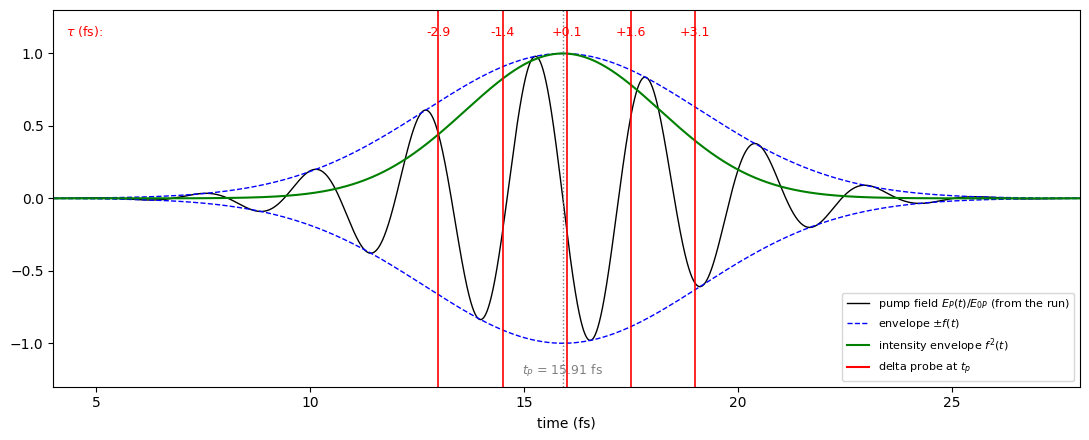

In [14]:
run = load_nl(os.path.join(nl_rt_dir,rt_id('3-6',6e9)))           # pump-only run
pump = run.Efield2[0]
t = np.array(run.IO_TIME_points)/Const.FsToAu
t_P = t_probes_nl[0]-tau_nl[t_probes_nl[0]]
sigma_P = pump['damping']/(2*np.sqrt(2*np.log(2)))/Const.FsToAu     # fs, damping = FWHM of f
f_P = np.exp(-(t-t_P)**2/(2*sigma_P**2))
fig,ax = plt.subplots(figsize=(11,4.5))
ax.plot(t,np.array(run.E_ext[0])[0].real/pump['amplitude'],'k',lw=1,label=r'pump field $E_P(t)/E_{0P}$ (from the run)')
ax.plot(t,f_P,'b--',lw=1,label=r'envelope $\pm f(t)$')
ax.plot(t,-f_P,'b--',lw=1)
ax.plot(t,f_P**2,'g',lw=1.5,label=r'intensity envelope $f^2(t)$')
for tp in t_probes_nl:
    ax.axvline(tp,color='r',lw=1.2)
    ax.text(tp,1.12,'%+.1f'%tau_nl[tp],color='r',ha='center',fontsize=9)
ax.text(4.3,1.12,r'$\tau$ (fs):',color='r',fontsize=9)
ax.axvline(t_P,color='gray',ls=':',lw=1)
ax.text(t_P,-1.22,r'$t_P$ = %.2f fs'%t_P,color='gray',ha='center',fontsize=9)
ax.plot([],[],'r',label=r'delta probe at $t_p$')
ax.set_xlim(4,28)
ax.set_ylim(-1.3,1.3)
ax.set_xlabel('time (fs)')
ax.legend(fontsize=8,loc='lower right')
plt.tight_layout()

chi3 vs RT third order (even part), 13.6-21.3 eV: rel. rms / ratio of the maxima / shift (eV)
tau (fs) | probe time               | local                    | accumulated             
   -2.91 | 0.36 / 0.69 / -0.00        | 0.41 / 1.38 / +0.02        | 0.17 / 1.07 / +0.01       
   -1.41 | 0.17 / 0.95 / +0.03        | 0.23 / 1.04 / +0.04        | 0.17 / 1.05 / +0.03       
    0.09 | 0.26 / 1.20 / +0.05        | 0.23 / 0.84 / +0.08        | 0.19 / 1.04 / +0.06       
    1.59 | 0.47 / 1.44 / +0.05        | 0.31 / 0.71 / +0.10        | 0.21 / 1.04 / +0.07       
    3.09 | 0.77 / 1.70 / +0.05        | 0.36 / 0.65 / +0.14        | 0.26 / 1.06 / +0.07       

accumulated weight on chi_(1,1,-1), other weights on the (1,+-2) terms: rel. rms / ratio of the maxima
(1,+-2) probe time: 0.19 / 1.11 | 0.17 / 1.04 | 0.20 / 1.07 | 0.26 / 1.10 | 0.34 / 1.11
(1,+-2) local     : 0.21 / 1.07 | 0.18 / 1.08 | 0.19 / 1.02 | 0.23 / 0.99 | 0.28 / 1.05
(1,+-2) none      : 0.43 / 1.23 | 0.36 / 0.98 | 0.39 / 0

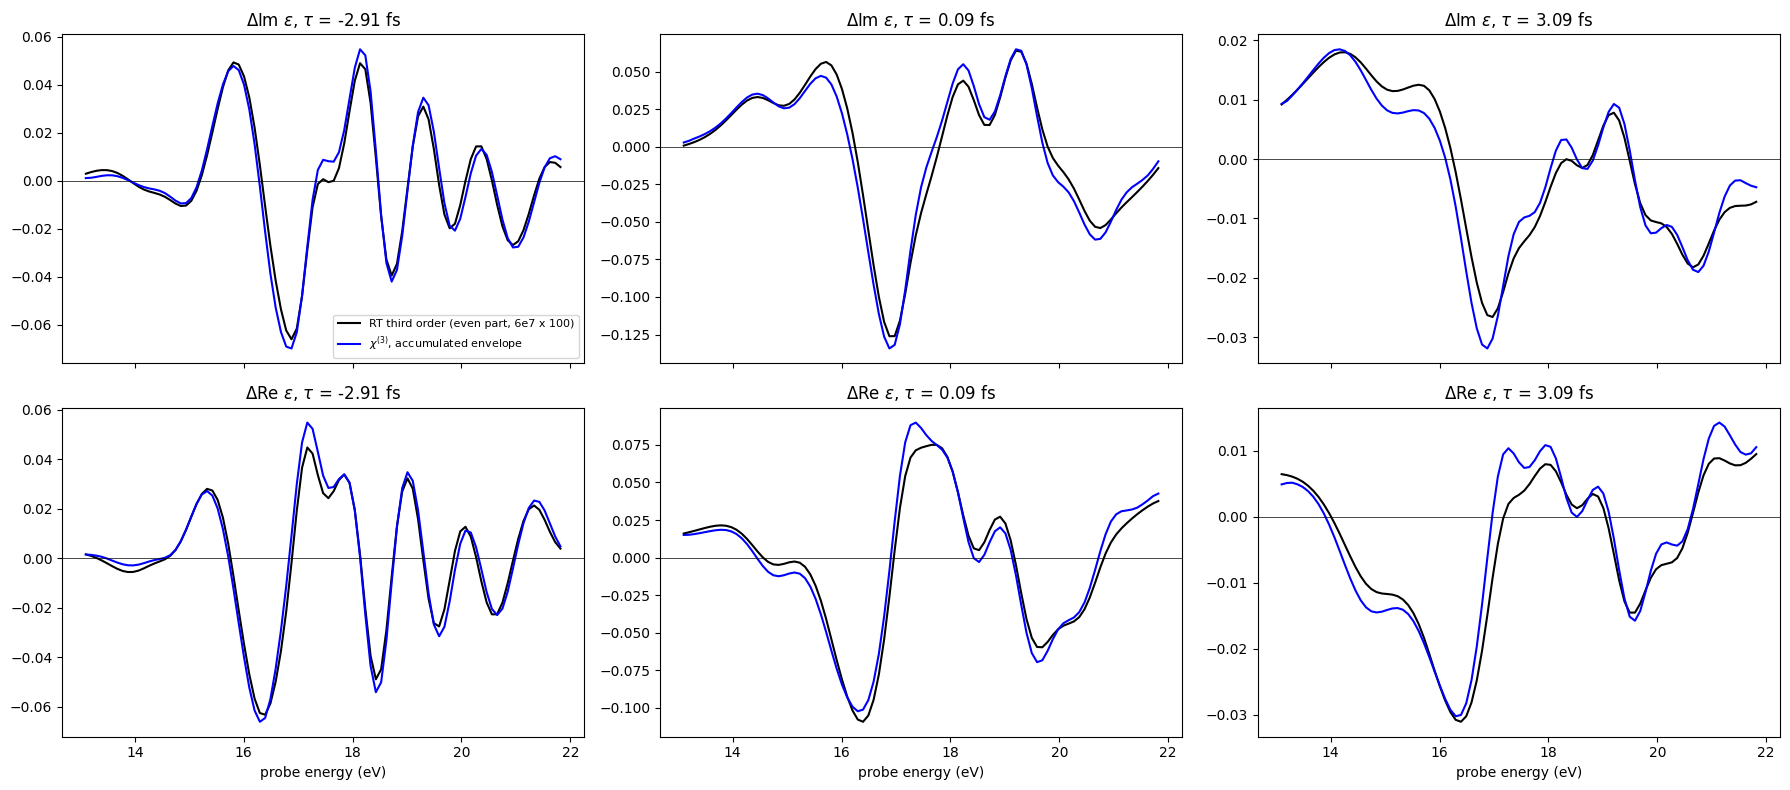

In [15]:
from mppi.Optics.Utils import time_weighted

def dchi_local(tr, taus, E0P, sigma, wP):
    # as tr.dchi(pump='accumulated') with the local weight f^2(tau+t) (pump at the emission time, not in MPPI): each term
    # weighted in time on the probe grid of the runs and read on the output grid
    f, n = tr.freqs/Const.HaToeV, int(round(2*tr.wP/tr.step))
    chi0 = (tr.keys[(1,0)]-tr.chi1)/(tr.E0P**2/4)
    out = []
    for tau in np.atleast_1d(taus):
        W = lambda t: np.exp(-((tau*Const.FsToAu+np.maximum(t,0))/(sigma*Const.FsToAu))**2)
        ph = np.exp(-2j*wP/Const.Planck_reduced_ev_fs*tau)
        out.append(E0P**2/4*(time_weighted(f,chi0,W)[n:-n] - time_weighted(f,tr.keys[(1,2)],W)[:-2*n]*ph
                             - time_weighted(f,tr.keys[(1,-2)],W)[2*n:]/ph))
    return tr.w, np.array(out)

def dchi_model(tr, taus, model):
    # dchi with the RT pump and the envelope weight model ('probe time', 'local', 'accumulated')
    if model == 'local': return dchi_local(tr,taus,E0P_rt,pump_rt['sigma'],pump_rt['freq'])
    return tr.dchi(taus,E0P_rt,pump=model,sigma=pump_rt['sigma'],wP=pump_rt['freq'])

taus_nl = [tau_nl[tp] for tp in t_probes_nl]
models = ['probe time','local','accumulated']
deps_chi_t = {}
for model in models:
    _, d = dchi_model(tr,taus_nl,model)
    for tp,y in zip(t_probes_nl,4*np.pi*invint_correction(w,d)): deps_chi_t[(model,tp)] = y
print('chi3 vs RT third order (even part), 13.6-21.3 eV: rel. rms / ratio of the maxima / shift (eV)')
print('tau (fs) | '+' | '.join('%-24s'%m for m in models))
for tp in t_probes_nl:
    print('%8.2f | '%tau_nl[tp]+' | '.join('%.2f / %.2f / %+.2f       '%compare(deps_chi_t[(m,tp)],even_nl[tp],(13.6,21.3)) for m in models))

# different weights on chi_(1,1,-1) and on the (1,+-2) terms: two instances with only one of them
zero = np.zeros_like(tr.chi1)
tr_0 = O.Transient_Response(tr.freqs,tr.chi1,{(1,0):tr.keys[(1,0)],(1,2):zero,(1,-2):zero},tr.E0P,tr.wP,verbose=False)
tr_2 = O.Transient_Response(tr.freqs,tr.chi1,{(1,0):tr.chi1,(1,2):tr.keys[(1,2)],(1,-2):tr.keys[(1,-2)]},tr.E0P,tr.wP,
                            verbose=False)
d_0 = dchi_model(tr_0,taus_nl,'accumulated')[1]
print('\naccumulated weight on chi_(1,1,-1), other weights on the (1,+-2) terms: rel. rms / ratio of the maxima')
for m2 in ['probe time','local','none']:
    d = 4*np.pi*invint_correction(w,d_0 + (0 if m2 == 'none' else dchi_model(tr_2,taus_nl,m2)[1]))
    print('(1,+-2) %-10s: '%m2+' | '.join('%.2f / %.2f'%compare(y,even_nl[tp],(13.6,21.3))[:2] for tp,y in zip(t_probes_nl,d)))

tps_env = [13.0,16.0,19.0]
fig,axes = plt.subplots(2,len(tps_env),figsize=(18,8),sharex=True)
for k,tp in enumerate(tps_env):
    for row,(part,lab) in enumerate([(np.imag,'Im'),(np.real,'Re')]):
        ax = axes[row,k]
        ax.plot(w,part(even_nl[tp]),'k',label='RT third order (even part, 6e7 x 100)')
        ax.plot(w,part(deps_chi_t[('accumulated',tp)]),'b',label=r'$\chi^{(3)}$, accumulated envelope')
        ax.axhline(0,color='k',lw=0.5)
        ax.set_title(r'$\Delta$%s $\epsilon$, $\tau$ = %.2f fs'%(lab,tau_nl[tp]))
axes[0,0].legend(fontsize=8)
for ax in axes[-1]: ax.set_xlabel('probe energy (eV)')
plt.tight_layout()

**Results.** The accumulated envelope removes the systematic error of the amplitude: the ratio of the maxima
$\chi^{(3)}$/RT goes from 0.69-1.70 (probe time) to 1.04-1.07 at all the delays, and the rel. rms from 0.17-0.77 to
0.17-0.26 in 13.6-21.3 eV. It also removes the sharp structures of the $\chi^{(3)}$ in 17-21 eV after the maximum (plot of the 6e7 even part above) (the time weight is a
convolution in frequency with the spectrum of the envelope, which smooths both the $\chi_{(1,1,-1)}$ and the $(1,\pm2)$ terms). The local weight overcorrects (ratio 1.38 before the maximum, 0.65-0.84 after it). The $(1,\pm2)$ terms are needed (without them the rms
doubles, 0.36-0.46), while their weight matters less: with the probe time or the local weight on them the rms is
0.17-0.34 and 0.18-0.28, the accumulated one is the best. With no
free parameter the $\chi^{(3)}$ of `yambo_nl` reproduces the third order RT response at all the delays; what is left
is a shift of 0.06-0.07 eV after the maximum and a $\sim$5% excess of the amplitude. The formula with the accumulated
envelope (`Transient_Response.dchi(pump='accumulated')`) replaces the one with the envelope at the probe time.

## Excitonic level: HARTREE+SEX

Same comparison as above (third order RT response vs $4\pi\delta\chi$ from the equilibrium $\chi$, figures 5 and 6 of the
notes) with the HARTREE+SEX dynamics (static screened exchange, collisions of D. Sangalli
`coll-par-cv_3-6B_X59RL-50B_noSM_H339RL_kpar`, bands 3-6, kx16), runs of `YamboNL_Analysis.ipynb` (Lumen `bug-fixes`):

- $\chi$: sine and P&p (pump 1e6 kW/cm$^2$) runs, 128 probe frequencies 7.85-20.15 eV with step $\omega_P/16$, damping
  0.6 eV in the dynamics (no a posteriori broadening), NLtime 40 fs, `NLstep` 0.01 fs, integrator CRANKNIC (ids
  `...-cn-nltime_40`). The output grid of the transient response is 10.95-17.05 eV (the probe grid minus $2\omega_P$ on
  each side). Pump 4e6 changes $\chi_0$ by 0.1% and $\chi_\pm$ by 0.3-0.4% (test runs): 1e6 is perturbative.
- RT: `rt-hsex-*` runs, same setup of the IP ones (CRANKNIC 3 as, no damping, delta probe at the five probe times, pump
  QSFIELD 6e7 and 6e9 kW/cm$^2$ along $\pm x$, pump-only and probe-only references), Lorentzian smoothing 0.6 eV of the
  spectra.

The HSEX exciton is at 12.9 eV (first maximum of Im $\epsilon$; edge 12.26 eV vs 15.87 eV in IP).

**Integrator.** The first HSEX $\chi$ runs used INVINT (ids `...-sin-nltime_40`, kept): with the SEX kernel INVINT adds a
spurious broadening of the exciton that grows with `NLstep` (delta runs with no damping: 0.39, 0.19, 0.09 eV at 0.01,
0.005, 0.0025 fs), so the $\chi$ with damping 0.6 eV looked like an RT spectrum with smoothing $\simeq$ 1 eV. CRANKNIC
with 0.01 fs has no such broadening: its delta run equals the RT probe-only one (CRANKNIC 3 as) within 0.7% once the
static energy map $E_{\rm eff} = (2\hbar/dt)\arctan(E\,dt/2\hbar)$ is removed; CRANKNIC has no field delay $dt/2$
(adding the phase of `invint_correction` gives 10%). So the CRANKNIC $\chi$ are corrected with `cranknic_correction`
(energy map only), not with `invint_correction`.

Probe frequencies: 128, from 7.850 to 20.153 eV, step 0.0969 eV
Pump of the frequency mixing runs: 1.5500 eV, amplitude 1.1936e-04 au
Orders of the terms included: [3] (centrosymmetric system)
Transient response defined from 10.950 to 17.053 eV (64 frequencies)
probe grid 7.850-20.153 eV (128), output grid 10.950-17.053 eV (64)


pump of the RT runs: {6000000000.0: {'E0P': np.float64(0.009246), 'sigma': np.float64(3.21893), 'wP': np.float64(1.56)}, 60000000.0: {'E0P': np.float64(0.000925), 'sigma': np.float64(3.21893), 'wP': np.float64(1.56)}}
tau (fs): [-2.91 -1.41  0.09  1.59  3.09]
eps_eq yambo_nl (no correction) vs RT probe-only, 10-20 eV: rel. rms 0.0412, edge shift (11-13.5 eV) +0.043 eV
eps_eq yambo_nl (cranknic_correction) vs RT probe-only, 10-20 eV: rel. rms 0.0046, edge shift (11-13.5 eV) +0.004 eV


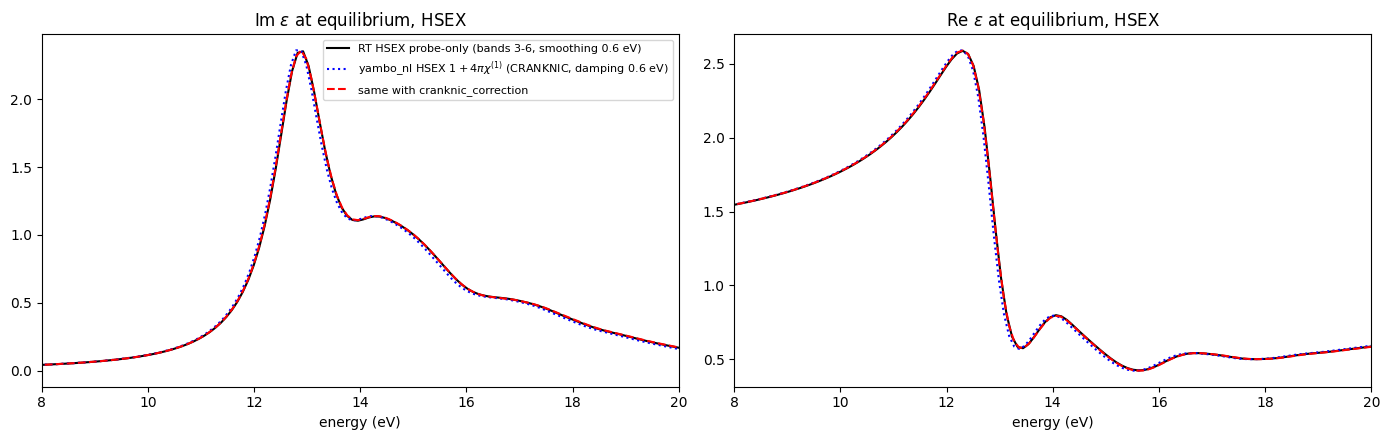

In [16]:
# chi at the HARTREE+SEX level (kx16, bands 3-6, damping 0.6 eV in the dynamics, no a posteriori broadening, CRANKNIC)
name_hsex = 'nlenrange_7.85-20.250-nlensteps_128-bands_3-6-damp_0.6-cn-nltime_40'
data_sine_h = load_nl(os.path.join(run_dir,'hsex-pulse-E1_1e3-'+name_hsex))
data_Pp_h = load_nl(os.path.join(run_dir,'hsex-Pp-Ep_1e3-EP_1e6-PE_1.55-'+name_hsex))
tr_h = O.Transient_Response.from_Xn(O.Xn_frequency_mixing(data_Pp_h,X_order=(1,2),verbose=False),
                                    O.Xn_single_frequency(data_sine_h,X_order=3,verbose=False),centrosymmetric=True)
w_h = tr_h.w
print('probe grid %.3f-%.3f eV (%d), output grid %.3f-%.3f eV (%d)'%(tr_h.freqs[0],tr_h.freqs[-1],len(tr_h.freqs),
      w_h[0],w_h[-1],len(w_h)))

def cranknic_correction(freqs, chi, dt=0.01):
    # removes the static energy map of the CRANKNIC integrator with time step dt (fs) from chi (last axis on the grid
    # freqs, eV): chi(w_eff), w_eff = (2 hbar/dt) arctan(w dt/2 hbar) (no field delay, unlike INVINT)
    hb = Const.Planck_reduced_ev_fs
    weff = 2*hb/dt*np.arctan(freqs*dt/(2*hb))
    chi = np.asarray(chi)
    out = [np.interp(weff,freqs,y.real)+1j*np.interp(weff,freqs,y.imag) for y in chi.reshape(-1,chi.shape[-1])]
    return np.array(out).reshape(chi.shape)

# RT runs with HARTREE+SEX (bands 3-6, collisions of D. Sangalli): Delta eps on the grid w_h, pump along +x and -x
hsex_id = lambda *a, **k: rt_id(*a,**k).replace('rt-ip-','rt-hsex-')
on_wh = lambda x, y: np.interp(w_h,x,y.real)+1j*np.interp(w_h,x,y.imag)
en_h, eps_eq_h = nl_eps(load_nl(os.path.join(nl_rt_dir,hsex_id('3-6',None,10.0))))
deps_h, tau_h, pump_h = {}, {}, {}
for I in I_nl:
    for neg in [False,True]:
        ref = load_nl(os.path.join(nl_rt_dir,hsex_id('3-6',I,neg=neg)))
        for tp in t_probes_nl:
            run = load_nl(os.path.join(nl_rt_dir,hsex_id('3-6',I,tp,neg)))
            deps_h[(I,neg,tp)], tau_h[tp] = on_wh(en_h,nl_eps(run,ref)[1]-eps_eq_h), nl_delay(run)
    p = ref.Efield2[0]
    pump_h[I] = dict(E0P=p['amplitude'],sigma=p['damping']/(2*np.sqrt(2*np.log(2)))/Const.FsToAu,
                     wP=p['freq_range'][0]*Const.HaToeV)
even_h = {(I,tp): (deps_h[(I,False,tp)]+deps_h[(I,True,tp)])/2 for I in I_nl for tp in t_probes_nl}
odd_h = {(I,tp): (deps_h[(I,False,tp)]-deps_h[(I,True,tp)])/2 for I in I_nl for tp in t_probes_nl}
taus_h = [tau_h[tp] for tp in t_probes_nl]
print('pump of the RT runs:',{I:{k:round(v,6) for k,v in p.items()} for I,p in pump_h.items()})
print('tau (fs):',np.round(taus_h,2))

# equilibrium: 1 + 4 pi chi1 (with and without the CRANKNIC correction) vs eps of the RT probe-only run
eq_rt = np.interp(tr_h.freqs,en_h,eps_eq_h.real)+1j*np.interp(tr_h.freqs,en_h,eps_eq_h.imag)
s = (tr_h.freqs>=10)&(tr_h.freqs<=20)
eps_nl_raw = 1+4*np.pi*tr_h.chi1
eps_nl_h = 1+4*np.pi*cranknic_correction(tr_h.freqs,tr_h.chi1)
for lab,e in [('no correction',eps_nl_raw),('cranknic_correction',eps_nl_h)]:
    print('eps_eq yambo_nl (%s) vs RT probe-only, 10-20 eV: rel. rms %.4f, edge shift (11-13.5 eV) %+.3f eV'%(lab,
          np.linalg.norm((e-eq_rt)[s])/np.linalg.norm((eq_rt-1)[s]),best_shift(tr_h.freqs,e.imag,tr_h.freqs,eq_rt.imag,(11,13.5))))
fig,axes = plt.subplots(1,2,figsize=(14,4.5))
for ax,part,lab in zip(axes,[np.imag,np.real],['Im','Re']):
    ax.plot(en_h,part(eps_eq_h),'k',label='RT HSEX probe-only (bands 3-6, smoothing 0.6 eV)')
    ax.plot(tr_h.freqs,part(eps_nl_raw),'b:',label=r'yambo_nl HSEX $1+4\pi\chi^{(1)}$ (CRANKNIC, damping 0.6 eV)')
    ax.plot(tr_h.freqs,part(eps_nl_h),'r--',label=r'same with cranknic_correction')
    ax.set_xlim(8,20); ax.set_xlabel('energy (eV)'); ax.set_title(r'%s $\epsilon$ at equilibrium, HSEX'%lab)
axes[0].legend(fontsize=8)
plt.tight_layout()

**Broadening.** With CRANKNIC the damping $\gamma$ = 0.6 eV of the $\chi$ runs and the smoothing $\eta$ = 0.6 eV of the RT
spectra are equivalent, as in the IP case (the fit of $\eta$ on the equilibrium spectrum gives 0.598 eV). The RT spectra
are therefore taken with $\eta$ = 0.6 eV, and $4\pi\delta\chi$ is corrected with `cranknic_correction` at the output
frequency (as `invint_correction` for the IP $\chi$).

In [17]:
# smoothing of the RT spectra equivalent to the damping of the HSEX chi runs (fit of eps_eq in 10-20 eV)
probe_only_h = load_nl(os.path.join(nl_rt_dir,hsex_id('3-6',None,10.0)))
def eq_dist(eta):
    e, y = nl_eps(probe_only_h,eta=eta)
    y = np.interp(tr_h.freqs,e,y.real)+1j*np.interp(tr_h.freqs,e,y.imag)
    return np.linalg.norm((eps_nl_h-y)[s])/np.linalg.norm((y-1)[s])
eta_eq_h = minimize_scalar(eq_dist,bounds=(0.4,1.0),method='bounded',options={'xatol':1e-3}).x
print('RT smoothing equivalent to the HSEX chi (damping 0.6 eV): %.3f eV (rel. rms %.4f; with 0.6 eV %.4f)'%(
      eta_eq_h,eq_dist(eta_eq_h),eq_dist(0.6)))

# dchi from the HSEX chi with the RT pumps (envelope at the probe time and accumulated), with and without the
# CRANKNIC correction
corrections_h = {'cn': cranknic_correction, 'none': lambda w, c: c}
deps_chi_h = {}
for I in I_nl:
    p = pump_h[I]
    for model in ['probe time','accumulated']:
        _, d = tr_h.dchi(taus_h,p['E0P'],pump=model,sigma=p['sigma'],wP=p['wP'])
        for cl,cf in corrections_h.items():
            for tp,y in zip(t_probes_nl,4*np.pi*cf(w_h,d)): deps_chi_h[(I,model,cl,tp)] = y

def compare_h(y, ref, erange=(11.,17.)):
    # rel. rms distance, ratio of the maxima and best rigid shift (eV) of y w.r.t. ref on the grid w_h in erange
    s = (w_h>=erange[0])&(w_h<=erange[1])
    sh = lambda a: np.interp(w_h[s]-a,w_h,y.real)+1j*np.interp(w_h[s]-a,w_h,y.imag)
    shift = minimize_scalar(lambda a: np.sum(np.abs(sh(a)-ref[s])**2),bounds=(-1,1),method='bounded').x
    return np.linalg.norm(y[s]-ref[s])/np.linalg.norm(ref[s]), np.abs(y[s]).max()/np.abs(ref[s]).max(), shift

s11 = (w_h>=11)&(w_h<=17)
for cl in corrections_h:
    print('\ncorrection of the chi: %s, 11-17 eV, rel. rms / ratio of the maxima / shift (eV)'%cl)
    print('tau (fs) | chi vs RT 6e7 even, probe time | accumulated | chi (acc.) vs RT 6e9 even')
    for tp in t_probes_nl:
        print('%+6.2f | %.2f / %.2f / %+.2f | %.2f / %.2f / %+.2f | %.2f / %.2f / %+.2f'%((tau_h[tp],)
              +compare_h(deps_chi_h[(6e7,'probe time',cl,tp)],even_h[(6e7,tp)])
              +compare_h(deps_chi_h[(6e7,'accumulated',cl,tp)],even_h[(6e7,tp)])
              +compare_h(deps_chi_h[(6e9,'accumulated',cl,tp)],even_h[(6e9,tp)])))
print('\nRT: max|odd|/max|even| at 6e7: %s, at 6e9: %s'%tuple(
      np.round([np.abs(odd_h[(I,tp)][s11]).max()/np.abs(even_h[(I,tp)][s11]).max() for tp in t_probes_nl],2) for I in [6e7,6e9]))
print('RT 6e9 even vs 6e7 even x 100 (rms / ratio / shift):',
      [tuple(np.round(compare_h(even_h[(6e9,tp)],100*even_h[(6e7,tp)]),2)) for tp in t_probes_nl])

RT smoothing equivalent to the HSEX chi (damping 0.6 eV): 0.598 eV (rel. rms 0.0040; with 0.6 eV 0.0046)

correction of the chi: cn, 11-17 eV, rel. rms / ratio of the maxima / shift (eV)
tau (fs) | chi vs RT 6e7 even, probe time | accumulated | chi (acc.) vs RT 6e9 even
 -2.91 | 0.40 / 0.59 / -0.00 | 0.03 / 1.01 / +0.00 | 0.58 / 1.58 / +0.06
 -1.41 | 0.11 / 0.94 / +0.00 | 0.02 / 1.00 / +0.00 | 0.58 / 1.55 / +0.06
 +0.09 | 0.31 / 1.42 / +0.02 | 0.03 / 1.03 / +0.00 | 0.43 / 1.39 / +0.06
 +1.59 | 0.84 / 2.22 / +0.03 | 0.08 / 1.10 / +0.01 | 0.26 / 1.26 / +0.04
 +3.09 | 1.58 / 3.56 / +0.04 | 0.16 / 1.21 / +0.02 | 0.22 / 1.26 / +0.02

correction of the chi: none, 11-17 eV, rel. rms / ratio of the maxima / shift (eV)
tau (fs) | chi vs RT 6e7 even, probe time | accumulated | chi (acc.) vs RT 6e9 even
 -2.91 | 0.42 / 0.62 / +0.04 | 0.22 / 1.06 / +0.05 | 0.75 / 1.65 / +0.12
 -1.41 | 0.21 / 0.97 / +0.04 | 0.18 / 1.03 / +0.04 | 0.73 / 1.60 / +0.13
 +0.09 | 0.41 / 1.47 / +0.05 | 0.18 / 1.06 / +0.05

In [18]:
def plot_dchi_hsex(I, models, title):
    # Delta eps at the five delays: RT even part (smoothing 0.6 eV) vs 4 pi dchi from the HSEX chi (cranknic_correction)
    fig,axes = plt.subplots(len(t_probes_nl),2,figsize=(13,2.6*len(t_probes_nl)),sharex=True)
    for k,tp in enumerate(t_probes_nl):
        for ax,part,lab in zip(axes[k],[np.real,np.imag],['Re','Im']):
            ax.plot(w_h,1e3*part(even_h[(I,tp)]),color='k',lw=1.3,label='RT HSEX even part, smoothing 0.6 eV')
            for m,(c,ls) in models.items():
                ax.plot(w_h,1e3*part(deps_chi_h[(I,m,'cn',tp)]),color=c,ls=ls,lw=1.1,
                        label=r'from the HSEX $\chi$, envelope '+m)
            ax.axhline(0,color='gray',lw=0.5)
            ax.set_ylabel(r'%s $\Delta\epsilon$ ($10^{-3}$)'%lab)
            ax.text(0.02,0.92,r'$\tau$ = %+.2f fs'%tau_h[tp],transform=ax.transAxes,va='top')
    for ax in axes[-1]: ax.set_xlabel('probe energy (eV)'); ax.set_xlim(w_h[0],w_h[-1])
    axes[0,0].legend(fontsize=7,loc='lower left')
    fig.suptitle(title)
    plt.tight_layout()
    return fig

Pump 6e7 kW/cm$^2$ (analog of Fig. 5 of the notes): RT third order response (even part in the pump field) vs
$4\pi\delta\chi$ with the envelope at the probe time and with the accumulated envelope.

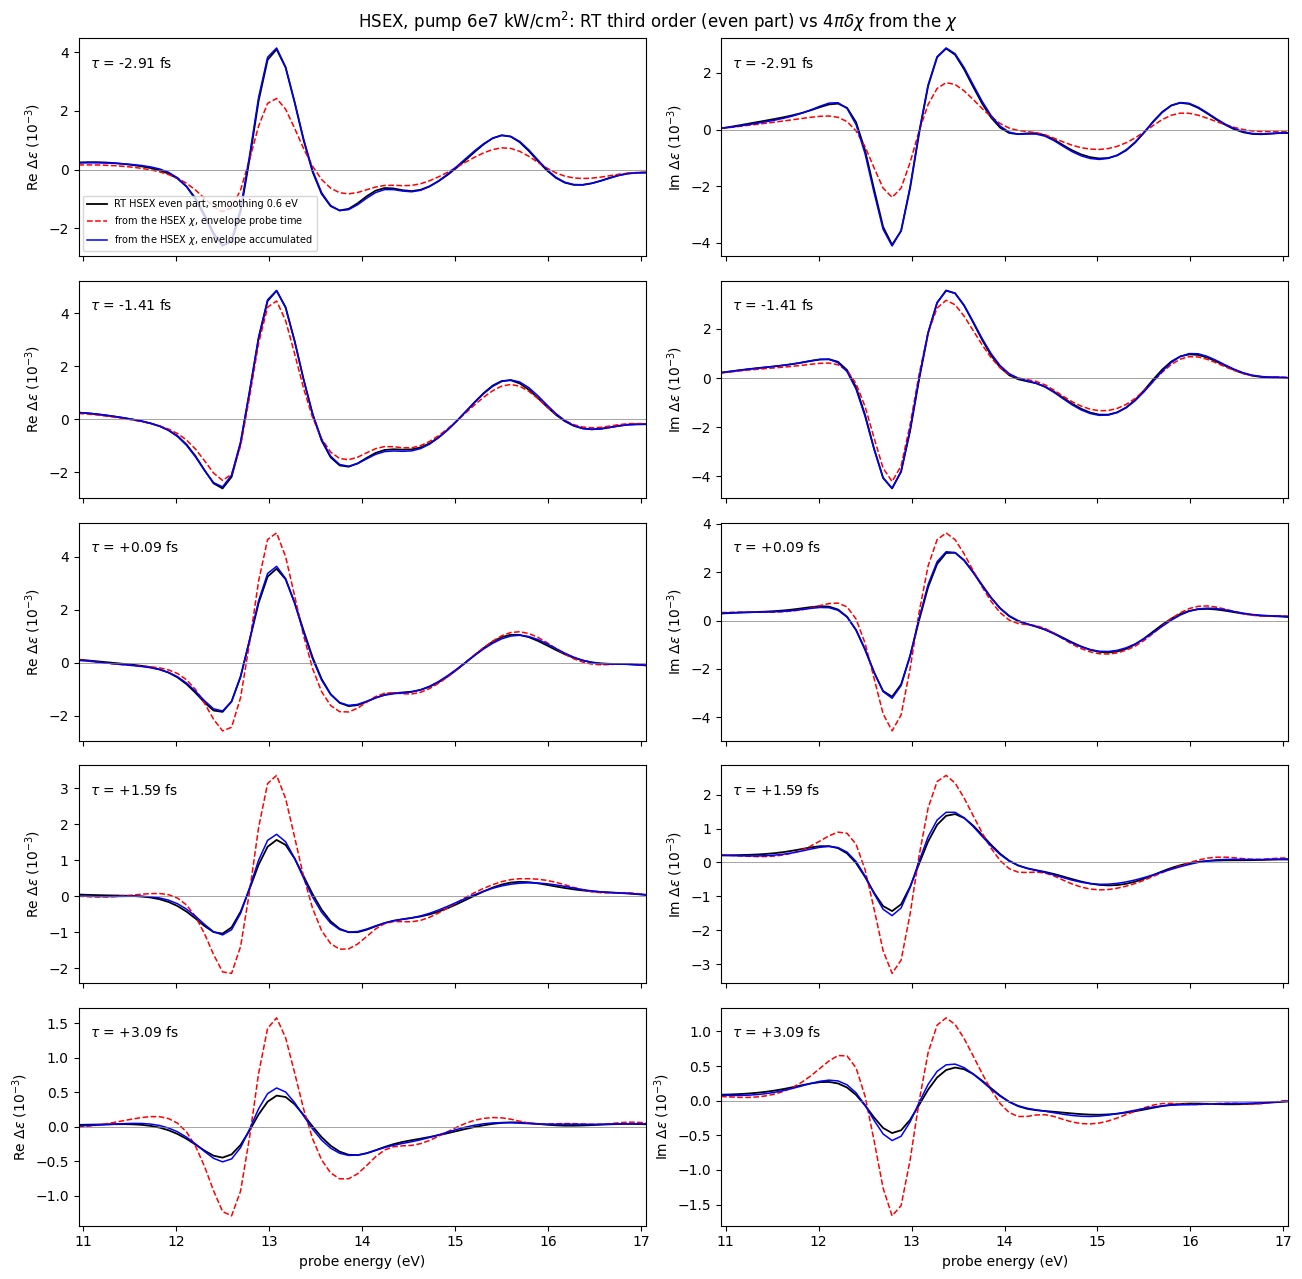

In [19]:
fig = plot_dchi_hsex(6e7,{'probe time':('r','--'),'accumulated':('b','-')},
                     r'HSEX, pump 6e7 kW/cm$^2$: RT third order (even part) vs $4\pi\delta\chi$ from the $\chi$')

Pump 6e9 kW/cm$^2$ (analog of Fig. 6 of the notes): RT even part vs $4\pi\delta\chi$ with the accumulated envelope.

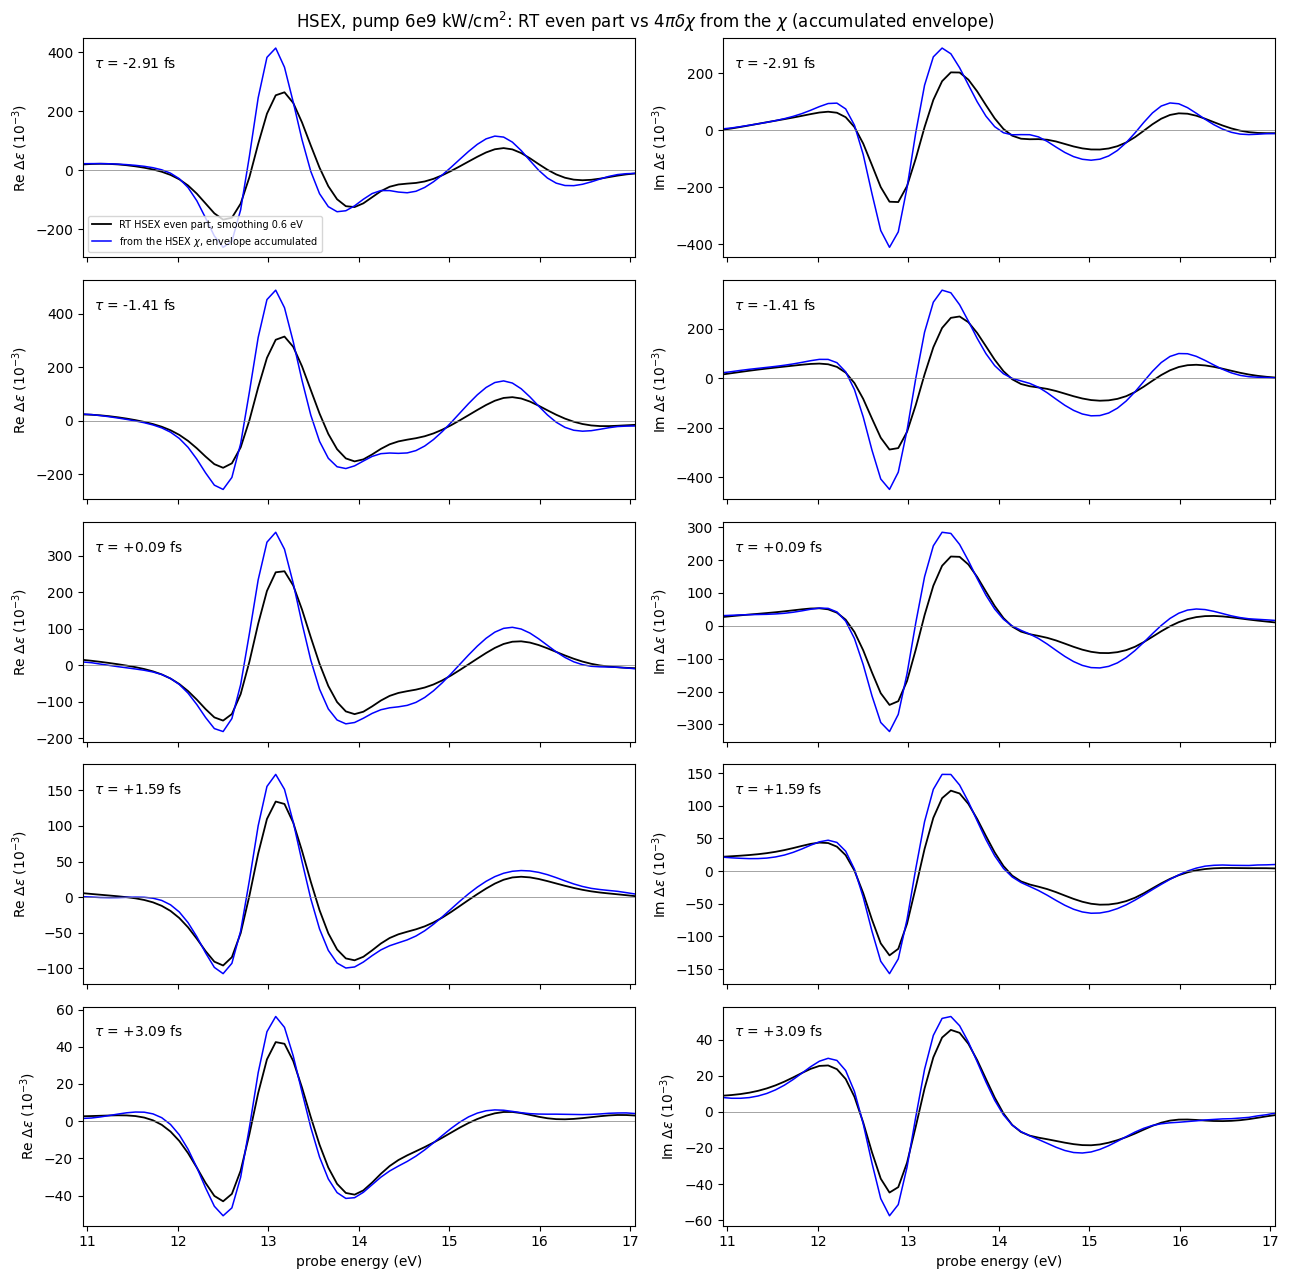

In [20]:
fig = plot_dchi_hsex(6e9,{'accumulated':('b','-')},
                     r'HSEX, pump 6e9 kW/cm$^2$: RT even part vs $4\pi\delta\chi$ from the $\chi$ (accumulated envelope)')

**Outcome (HSEX, CRANKNIC $\chi$, 11-17 eV).** At equilibrium $1+4\pi\chi^{(1)}$ with `cranknic_correction` equals the RT
probe-only spectrum within 0.5% (4.1% and 0.04 eV without the correction). Pump 6e7 kW/cm$^2$, third order RT (even
part) vs $4\pi\delta\chi$:

| $\tau$ (fs) | probe time: rms / ratio | accumulated: rms / ratio / shift (eV) |
|---|---|---|
| -2.91 | 0.40 / 0.59 | 0.03 / 1.01 / 0.00 |
| -1.41 | 0.11 / 0.94 | 0.02 / 1.00 / 0.00 |
| +0.09 | 0.31 / 1.42 | 0.03 / 1.03 / 0.00 |
| +1.59 | 0.84 / 2.22 | 0.08 / 1.10 / +0.01 |
| +3.09 | 1.58 / 3.56 | 0.16 / 1.21 / +0.02 |

With the accumulated envelope the HSEX $\chi$ reproduce the RT third order response at 2-3% up to the pump maximum,
better than in IP; after the maximum the $\chi$ overestimate by 10-20%. Without the correction the rms is 0.18-0.27 (shift
0.05 eV). The odd part of the RT runs at 6e7 is 0.44-1.29 of the even one (as in IP). At 6e9 the RT even part is
26-36% smaller than 100 times the 6e7 one before the maximum and recovers it at +3.09 fs (5% smaller): the $\chi$
with the accumulated envelope are larger by 26-58% (rms 0.22-0.58), as in IP the RT at 6e9 is beyond third order.

### Maps vs the delay: RT of D. Sangalli vs the HSEX $\chi$

Transient response at the HSEX level as a map vs the delay (x) and the probe energy (y), from the RT runs of
D. Sangalli and from the $\chi$, as the RT IP maps at the beginning of the notebook ($\Delta$Im $\epsilon$ only).

- **RT.** HSEX runs of D. Sangalli (`td-hsex-cv-ber_*`): bands 3-12, the same collisions as our runs, QSFIELD pump
  1.56 eV, $\sigma$ = 3.219 fs, 6e9 kW/cm$^2$ along +x, smoothing 0.6 eV. 61 runs: the reference at -10.66 fs (his
  earliest delay) and 60 delays from -7.41 to +7.34 fs with step 0.25 fs (5.3 points per period of the oscillations at
  $2\omega_P$, 1.33 fs). Only the pump along +x: it is the total response, not the even part (in our runs at 6e9 the
  odd part is 4-9% of the even one).
- **$\chi$.** HSEX $\chi$ (bands 3-6, CRANKNIC, `cranknic_correction`), accumulated envelope, pump of the RT runs at
  6e9, the same delays and reference (at -10.66 fs $\delta\chi$ is $\sim 10^{-5}$ of its maximum, so the reference is
  the equilibrium spectrum $1+4\pi\chi^{(1)}$). $\epsilon = 1+4\pi(\chi^{(1)}+\delta\chi)$ on the output grid
  10.95-17.05 eV, interpolated (cubic spline) on a 0.02 eV grid; the RT spectra are interpolated on the same grid
  (11-17 eV).
- The $\chi$ map is third order: at 6e7 kW/cm$^2$ it is the 6e9 one divided by 100. At 6e9 the RT is beyond the third
  order (our RT even part is 26-36% smaller than 100 times the 6e7 one before the pump maximum, see the outcome of the
  HSEX comparison above).

Figure: $\Delta$Im $\epsilon$ of the RT and of the $\chi$ (same color scale) and the spectra at the delay nearest to the
pump maximum ($\tau$ = 0.09 fs, dashed line).

In [21]:
from scipy.interpolate import CubicSpline

def chi_runs_hsex(I, taus, de=0.02, pump='accumulated'):
    # runs-like dict (as load_rt_runs) of eps = 1 + 4 pi (chi1 + dchi) from the HSEX chi at the delays taus (fs), with the
    # pump of the RT runs at intensity I, on a grid of step de (eV) in the output range w_h (cubic spline)
    p = pump_h[I]
    _, d = tr_h.dchi(taus,p['E0P'],pump=pump,sigma=p['sigma'],wP=p['wP'])
    eps = 1+4*np.pi*(on_wh(tr_h.freqs,cranknic_correction(tr_h.freqs,tr_h.chi1))+cranknic_correction(w_h,d))
    E = np.arange(w_h[0],w_h[-1]+1e-9,de)
    return dict(energy=E,eps=CubicSpline(w_h,eps,axis=1)(E),tau=np.asarray(taus),pump=p)

# RT HSEX runs of D. Sangalli (bands 3-12, pump 6e9 kW/cm^2 along +x) and the chi at the same delays (the first one is
# the reference): Delta Im eps on the energy grid of the chi map in 11-17 eV, without the reference
rt_hx = load_rt_runs('td-hsex-cv-ber')
map_chi = chi_runs_hsex(6e9,rt_hx['tau'])
tau_m = rt_hx['tau'][1:]
E_m = map_chi['energy'][(map_chi['energy'] >= 11) & (map_chi['energy'] <= 17)]
dim_rt = np.array([np.interp(E_m,rt_hx['energy'],y) for y in rt_quantity(rt_hx,'Im eps',change=True)[1:]])
dim_chi = np.array([np.interp(E_m,map_chi['energy'],y) for y in rt_quantity(map_chi,'Im eps',change=True)[1:]])
print('RT HSEX of D. Sangalli: reference %.2f fs, %d delays %.2f..%.2f fs, pump %s'%(rt_hx['tau'][0],len(tau_m),
      tau_m[0],tau_m[-1],rt_hx['pump']))
print('RT (D. Sangalli, bands 3-12) vs chi (bands 3-6, accumulated envelope), pump 6e9, Delta Im eps in 11-17 eV: '
      'rel. rms / ratio of the maxima RT/chi')
wins = {'all':np.ones(len(tau_m),bool),'tau < -1.5':tau_m < -1.5,'|tau| < 1.5':np.abs(tau_m) < 1.5,'tau > 1.5':tau_m > 1.5}
print(' | '.join('%s: %.2f / %.2f'%(k,np.linalg.norm(dim_rt[m]-dim_chi[m])/np.linalg.norm(dim_chi[m]),
                 np.abs(dim_rt[m]).max()/np.abs(dim_chi[m]).max()) for k,m in wins.items()))

RT HSEX of D. Sangalli: reference -10.66 fs, 60 delays -7.41..7.34 fs, pump {'freq': 1.56, 'sigma': 3.21892962, 'intensity': 6000000000.0}
RT (D. Sangalli, bands 3-12) vs chi (bands 3-6, accumulated envelope), pump 6e9, Delta Im eps in 11-17 eV: rel. rms / ratio of the maxima RT/chi
all: 0.21 / 0.80 | tau < -1.5: 0.23 / 0.80 | |tau| < 1.5: 0.18 / 0.85 | tau > 1.5: 0.24 / 1.12


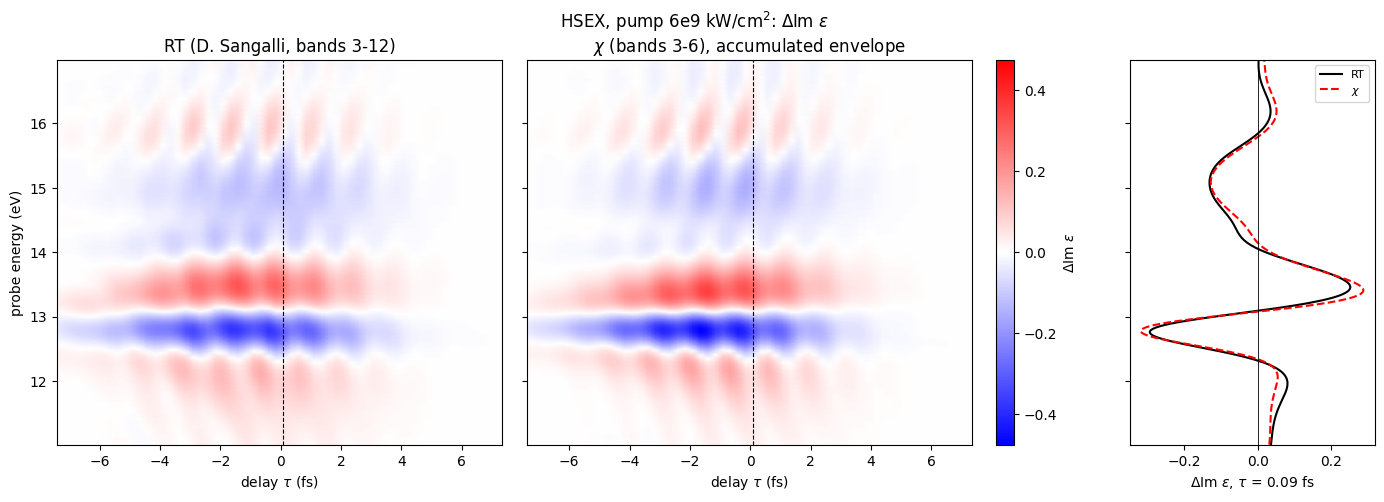

In [22]:
tau_cut = 0.
i = np.argmin(np.abs(tau_m-tau_cut))
vmax = max(np.abs(dim_rt).max(),np.abs(dim_chi).max())
fig = plt.figure(figsize=(17,5))
gs = fig.add_gridspec(1,5,width_ratios=[2,2,0.08,0.3,1.1],wspace=0.1)
axes = [fig.add_subplot(gs[0])]
axes += [fig.add_subplot(gs[k],sharey=axes[0]) for k in [1,4]]
for ax,d,t in zip(axes[:2],[dim_rt,dim_chi],['RT (D. Sangalli, bands 3-12)',r'$\chi$ (bands 3-6), accumulated envelope']):
    pc = ax.pcolormesh(tau_m,E_m,d.T,cmap='bwr',norm=TwoSlopeNorm(0,-vmax,vmax),shading='gouraud')
    ax.axvline(tau_m[i],color='k',lw=0.8,ls='--')
    ax.set_xlabel(r'delay $\tau$ (fs)'); ax.set_title(t)
fig.colorbar(pc,cax=fig.add_subplot(gs[2]),label=r'$\Delta$Im $\epsilon$')
axes[0].set_ylabel('probe energy (eV)')
axes[2].plot(dim_rt[i],E_m,'k',label='RT')
axes[2].plot(dim_chi[i],E_m,'r--',label=r'$\chi$')
axes[2].axvline(0,color='k',lw=0.6)
axes[2].set_xlabel(r'$\Delta$Im $\epsilon$, $\tau$ = %.2f fs'%tau_m[i]); axes[2].legend(fontsize=8)
for ax in axes[1:]: ax.tick_params(labelleft=False)
fig.suptitle(r'HSEX, pump 6e9 kW/cm$^2$: $\Delta$Im $\epsilon$');

**Outcome (HSEX, pump 6e9 kW/cm$^2$, $\Delta$Im $\epsilon$ in 11-17 eV).** The $\chi$ map has the structures of the
RT one: bleach at 12.8 eV and induced absorption at 13.4 eV, the negative band at ~15 eV and the positive one at
~16 eV, and the fringes at $2\omega_P$ with the same tilt (next section). Rel. rms 0.21 over the 60 delays (0.23 before
the pump maximum, $\tau$ < -1.5 fs; 0.18 around it, $|\tau|$ < 1.5 fs; 0.24 after it), ratio of the maxima RT/$\chi$
0.80 / 0.85 / 1.12 in the same windows: the RT is smaller than the third order up to the pump maximum and slightly
larger after it. At $\tau$ = 0.09 fs the two spectra have the same shape. With our RT runs (bands 3-6, even part) the
$\chi$ were larger by 26-58% (above); the RT with the bands 3-12 is 20-30% larger than the one with 3-6 at 6e9, so the
better agreement here is partly a compensation between the bands above 6 and the orders above the third.

### Oscillations at $\pm2\omega_P$: RT vs the AC part of the $\chi$ (HSEX, pump 6e9 kW/cm$^2$)

With a delta probe the third order response contains, besides the term $\chi_0$, the terms $\chi_\pm$ that oscillate
with the delay as $e^{\mp2i\omega_P\tau}$:
$$\delta\chi(\omega,\tau) = \frac{E_{0P}^2}{4}\left[\chi_0(\omega) - \chi_+(\omega)e^{-2i\omega_P\tau}
- \chi_-(\omega)e^{2i\omega_P\tau}\right]$$
(monochromatic pump; with the Gaussian pump each term is weighted by the envelope, here the accumulated one). The
$\chi_0$ term (DC part) follows the pump envelope; the $\chi_\pm$ terms (AC part) give the fringes visible in the maps.
They depend on where in the optical cycle of the pump the probe arrives; the period is $\pi/\omega_P$ = 1.33 fs, half
the pump period, because the third order is even in $E_P$. Only a probe shorter than the pump cycle sees them: the DC
part is the average over the cycle.

The fringes of the maps of the previous section (RT of D. Sangalli and $\chi$ at the same 60 delays) are isolated as
follows.

- **$\chi$.** The AC part is computed directly from the formula without $\chi_0$: a `Transient_Response` with the key
  (1,0) equal to $\chi^{(1)}$ (so $\chi_0$ = 0) and the keys $(1,\pm2)$ of the HSEX runs, accumulated envelope, pump of
  the RT runs at 6e9, `cranknic_correction`.
- **RT.** The two parts cannot be separated in the RT response. At each probe energy the part that follows the
  envelope is removed with a high-pass filter in the delay: the series $y(\tau_i)$ = Im $\Delta\epsilon(\omega,\tau_i)$
  minus its Gaussian smoothing,
  $$y_{hp}(\tau_i) = y(\tau_i) - \frac{\sum_j K_{ij}\,y(\tau_j)}{\sum_j K_{ij}},\qquad
  K_{ij} = e^{-(\tau_i-\tau_j)^2/2s^2},\quad s = 0.55\ \mathrm{fs}.$$
  The smoothing keeps $e^{-(2\omega_P s)^2/2}$ = 3% of the oscillation at $2\omega_P$ (4.74 rad/fs) and almost all of
  the part that follows the envelope ($f^2$ has a width $\sigma/\sqrt2$ = 2.3 fs). The filter is checked on the $\chi$
  map, where the AC part is known (printed below).
- **$2\omega_P$ component.** At each probe energy the AC signal $y(\tau)$ (RT after the high-pass, or AC part of the
  $\chi$) is an oscillation at $2\omega_P$ whose amplitude follows the pump envelope. It is described by one complex
  number $a(\omega)$, i.e. two real numbers, the amplitude $|a|$ and the phase $\arg a$:
  $$y(\omega,\tau) \simeq f^2(\tau)\,\mathrm{Re}\left[a(\omega)\,e^{2i\omega_P\tau}\right]
  = f^2(\tau)\,|a(\omega)|\cos\left(2\omega_P\tau+\arg a(\omega)\right),\qquad f^2(\tau) = e^{-\tau^2/\sigma^2}.$$
  $|a|$ is the amplitude of the oscillation at the pump maximum ($\tau$ = 0), the phase fixes the delays of the crests,
  $\tau_k = (2\pi k-\arg a)/2\omega_P$. $a$ is the least squares fit of this form to the signal (frequency and envelope
  fixed), i.e. the projection of $y$ on $e^{2i\omega_P\tau}$ with the weight $f^2$:
  $$a(\omega) = 2\,\frac{\sum_i y(\omega,\tau_i)\,f^2(\tau_i)\,e^{-2i\omega_P\tau_i}}{\sum_i f^4(\tau_i)},
  \qquad |\tau_i| < 6\ \mathrm{fs}$$
  (inserting the form above gives $a$ plus a term at $4\omega_P$ that averages out). The envelope of the signals is not
  exactly $f^2$ (it is asymmetric and peaks slightly before the pump maximum), so $|a|$ is a weighted average of the
  amplitude around the pump maximum. The same projection at $n\omega_P$ ($n$ = 1, 3, 4) measures the other components
  of the RT signal (the third order $\chi$ has only $n$ = 2).

First figure: (1) Im $\Delta\epsilon$ of the RT after the high-pass and (2) the AC part of the $\chi$, same color scale;
(3) $|a|$ vs the probe energy, the amplitude of the fringes at the pump maximum along a vertical line of panels 1-2;
(4) $\arg a$ vs the probe energy (continuous in the energy). Where the phase is the same for RT and $\chi$ the crests are
at the same delays (a difference of 0.1 rad moves them by 0.02 fs). The slope of the phase gives the tilt of the
fringes, $d\tau_k/d\omega = -(d\arg a/d\omega)/2\omega_P$: a phase change of $2\pi$ over an energy interval moves the
crests by one period (1.33 fs) across it. A fast change of the phase by $\sim\pi$ where $|a|$ goes to zero (14.6 eV)
means that the fringes above and below are in antiphase.

Second figure: the AC signal vs the delay at four probe energies: RT after the high-pass at its delays (dots), its fit
$f^2|a|\cos(2\omega_P\tau+\arg a)$ (black line, envelope $\pm|a|f^2$ dotted) and the AC part of the $\chi$ on a 0.02 fs
grid (red). The values of $|a|$ and $\arg a$ in the titles are those of panels 3 and 4 at that energy.

In [23]:
# Im Delta eps of the RT runs of D. Sangalli (previous section) on the grid w_h, without the reference
taus_ds = rt_hx['tau'][1:]
im_rt = np.array([np.interp(w_h,rt_hx['energy'],y) for y in rt_quantity(rt_hx,'Im eps',change=True)[1:]])

# AC part from the chi: only the chi_+- terms (key (1,0) = chi1, i.e. chi_0 = 0), pump of the RT runs at 6e9
tr_h_ac = O.Transient_Response(tr_h.freqs,tr_h.chi1,{(1,0):tr_h.chi1,(1,2):tr_h.keys[(1,2)],(1,-2):tr_h.keys[(1,-2)]},
                               tr_h.E0P,tr_h.wP,verbose=False)
p6 = pump_h[6e9]
def im_deps_chi(taus, tr=tr_h_ac, pump='accumulated'):
    # Im 4 pi dchi (cranknic_correction) at the delays taus (fs), pump of the RT runs at 6e9
    _, d = tr.dchi(taus,p6['E0P'],pump=pump,sigma=p6['sigma'],wP=p6['wP'])
    return (4*np.pi*cranknic_correction(w_h,d)).imag
ac_chi, full_chi = im_deps_chi(taus_ds), im_deps_chi(taus_ds,tr=tr_h)

W2 = 2*p6['wP']/Const.Planck_reduced_ev_fs                           # 2 omega_P (rad/fs)

def highpass(y, t, s=0.55):
    # y (delays, energies) minus its Gaussian smoothing in the delay t (width s, fs): removes the part that follows
    # the pump envelope, keeps the oscillations at 2 omega_P (the smoothing keeps exp(-(2 omega_P s)^2/2) = 0.03 of them)
    K = np.exp(-(t[:,None]-t[None,:])**2/(2*s**2))
    return y-(K@y)/K.sum(1)[:,None]

def demod(y, t, n=2, s=None):
    # complex amplitude a(w) of the component at n omega_P, y = f^2(tau) Re[a e^{i n omega_P tau}], from the delays
    # selected by s (default |tau| < 6 fs) weighted by the pump envelope f^2 = exp(-tau^2/sigma^2): |a| is the amplitude
    # of the oscillation at the pump maximum, the crests are at n omega_P tau + arg a = 2 pi k
    s = np.abs(t) < 6 if s is None else s
    g = np.exp(-t[s]**2/p6['sigma']**2)
    return 2*(y[s]*(g*np.exp(-0.5j*n*W2*t[s]))[:,None]).sum(0)/(g**2).sum()

hp_rt, hp_ac, hp_full = highpass(im_rt,taus_ds), highpass(ac_chi,taus_ds), highpass(full_chi,taus_ds)
a_rt, a_chi, a_hp, a_full = [demod(y,taus_ds) for y in [hp_rt,ac_chi,hp_ac,hp_full]]
big = np.abs(a_chi) > 0.5*np.abs(a_chi).max()                       # energies with a large 2 omega_P component
ph_rt, ph_chi = np.unwrap(np.angle(a_rt)), np.unwrap(np.angle(a_chi))  # phases continuous in the energy
sel = np.abs(taus_ds) < 3
rel = lambda x, y: np.linalg.norm((x-y)[sel])/np.linalg.norm(y[sel])
# checks of the filter on the chi map, where the AC part is known: attenuation of the AC part, leak of the chi_0 part
print('filter on the chi map (|tau| < 3 fs, 11-17 eV): rel. rms w.r.t. the AC part %.3f (high-pass of the AC part), '
      '%.3f (high-pass of the full map); 2 omega_P amplitude kept %.3f, phase changed by <= %.3f rad'%(rel(hp_ac,ac_chi),
      rel(hp_full,ac_chi),np.median(np.abs(a_full/a_chi)[big]),np.abs(np.angle(a_full/a_chi)[big]).max()))
print('RT high-pass vs chi AC part (|tau| < 3 fs, 11-17 eV): rel. rms %.2f, ratio of the maxima %.2f'%(
      rel(hp_rt,ac_chi),np.abs(hp_rt[sel]).max()/np.abs(ac_chi[sel]).max()))
print('components at n omega_P of the RT high-pass, max over w of |a| (chi: only n = 2): '+
      ', '.join('n=%d %.4f'%(n,np.abs(demod(hp_rt,taus_ds,n)).max()) for n in [1,2,3,4]))
a_pt = demod(im_deps_chi(taus_ds,pump='probe time'),taus_ds)
print('chi AC part with the envelope at the probe time / accumulated: |a| ratio %.2f-%.2f, phase difference <= %.2f rad'%(
      np.abs(a_pt/a_chi).min(),np.abs(a_pt/a_chi).max(),np.abs(np.angle(a_pt/a_chi)).max()))
print('\n2 omega_P component: amplitude |a| at the pump maximum, phase arg a (crests at 2 omega_P tau + arg a = 2 pi k)')
print(' w (eV) | |a| RT | |a| chi AC | RT / chi (same filter) | arg a RT - chi (rad)')
for wi in [11.5,12.3,12.9,13.5,14.0,14.6,15.0,15.5,16.0,16.5]:
    i = np.argmin(abs(w_h-wi))
    print(' %5.2f  | %.4f |   %.4f   |          %.2f          |   %+.2f'%(w_h[i],abs(a_rt[i]),abs(a_chi[i]),
          abs(a_rt[i]/a_hp[i]),np.angle(a_rt[i]/a_chi[i])))
print('RT / chi (same filter) by delay window, median over the energies with a large component:',
      ', '.join('%s %.2f'%(k,np.median(np.abs(demod(hp_rt,taus_ds,s=m)/demod(hp_ac,taus_ds,s=m))[big])) for k,m in
                [('tau < -1.5 fs',taus_ds < -1.5),('|tau| < 1.5 fs',np.abs(taus_ds) < 1.5),('tau > 1.5 fs',taus_ds > 1.5)]))

filter on the chi map (|tau| < 3 fs, 11-17 eV): rel. rms w.r.t. the AC part 0.039 (high-pass of the AC part), 0.096 (high-pass of the full map); 2 omega_P amplitude kept 0.963, phase changed by <= 0.005 rad
RT high-pass vs chi AC part (|tau| < 3 fs, 11-17 eV): rel. rms 0.39, ratio of the maxima 0.88
components at n omega_P of the RT high-pass, max over w of |a| (chi: only n = 2): n=1 0.0093, n=2 0.0716, n=3 0.0051, n=4 0.0034
chi AC part with the envelope at the probe time / accumulated: |a| ratio 0.98-1.09, phase difference <= 0.06 rad

2 omega_P component: amplitude |a| at the pump maximum, phase arg a (crests at 2 omega_P tau + arg a = 2 pi k)
 w (eV) | |a| RT | |a| chi AC | RT / chi (same filter) | arg a RT - chi (rad)
 11.53  | 0.0073 |   0.0181   |          0.42          |   -0.03
 12.31  | 0.0540 |   0.0684   |          0.82          |   +0.01
 12.89  | 0.0400 |   0.0509   |          0.82          |   +0.09
 13.47  | 0.0436 |   0.0423   |          1.07          |   -0.07
 13.95 

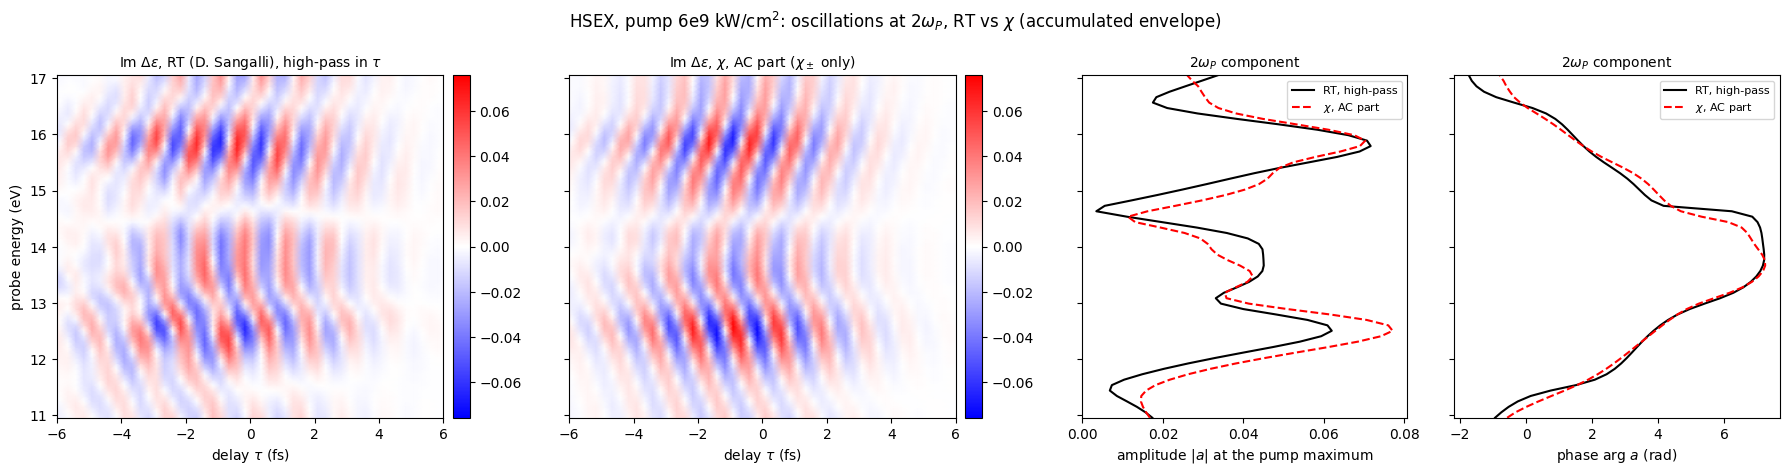

In [24]:
fig,axes = plt.subplots(1,4,figsize=(18,4.8),sharey=True,gridspec_kw=dict(width_ratios=[1,1,0.7,0.7]))
v = np.abs(ac_chi).max()
for ax,y,t in zip(axes[:2],[hp_rt,ac_chi],['RT (D. Sangalli), high-pass in $\\tau$',r'$\chi$, AC part ($\chi_\pm$ only)']):
    pc = ax.pcolormesh(taus_ds,w_h,y.T,cmap='bwr',norm=TwoSlopeNorm(0,-v,v),shading='gouraud')
    fig.colorbar(pc,ax=ax,pad=0.02)
    ax.set_title(r'Im $\Delta\epsilon$, '+t,fontsize=10)
    ax.set_xlabel(r'delay $\tau$ (fs)'); ax.set_xlim(-6,6)
axes[0].set_ylabel('probe energy (eV)')
axes[2].plot(np.abs(a_rt),w_h,'k',label='RT, high-pass')
axes[2].plot(np.abs(a_chi),w_h,'r--',label=r'$\chi$, AC part')
axes[2].set_xlabel(r'amplitude $|a|$ at the pump maximum'); axes[2].legend(fontsize=8)
axes[3].plot(ph_rt,w_h,'k',label='RT, high-pass')
axes[3].plot(ph_chi,w_h,'r--',label=r'$\chi$, AC part')
axes[3].set_xlabel(r'phase arg $a$ (rad)'); axes[3].legend(fontsize=8)
for ax in axes[2:]: ax.set_title(r'$2\omega_P$ component',fontsize=10)
axes[0].set_ylim(w_h[0],w_h[-1])
fig.suptitle(r'HSEX, pump 6e9 kW/cm$^2$: oscillations at $2\omega_P$, RT vs $\chi$ (accumulated envelope)')
plt.tight_layout()

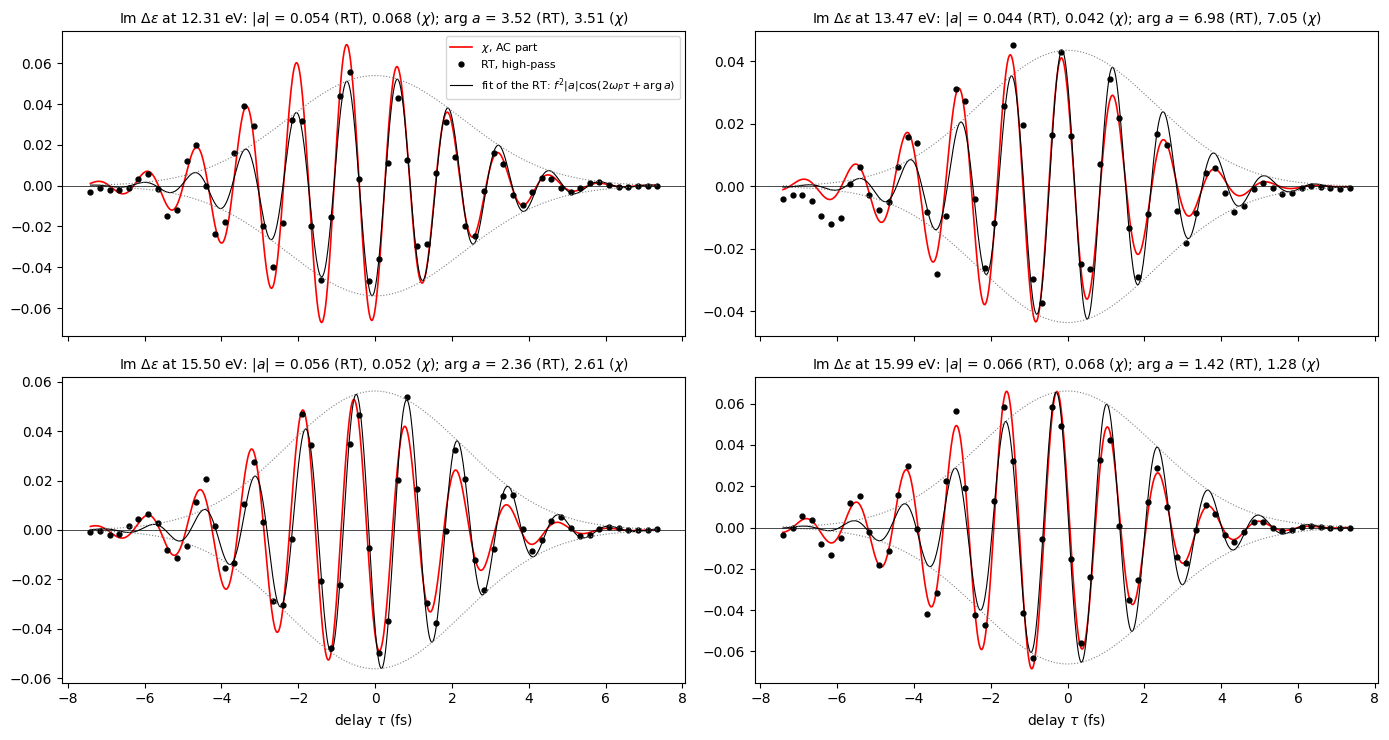

In [25]:
taus_fine = np.arange(taus_ds[0],taus_ds[-1]+1e-9,0.02)
ac_fine = im_deps_chi(taus_fine)
f2 = np.exp(-taus_fine**2/p6['sigma']**2)
fig,axes = plt.subplots(2,2,figsize=(14,7.5),sharex=True)
for ax,wi in zip(axes.flat,[12.3,13.5,15.5,16.0]):
    i = np.argmin(abs(w_h-wi))
    ax.plot(taus_fine,ac_fine[:,i],'r',lw=1.2,label=r'$\chi$, AC part')
    ax.plot(taus_ds,hp_rt[:,i],'ko',ms=3.5,label='RT, high-pass')
    ax.plot(taus_fine,f2*(a_rt[i]*np.exp(1j*W2*taus_fine)).real,'k',lw=0.8,
            label=r'fit of the RT: $f^2|a|\cos(2\omega_P\tau+\arg a)$')
    for sgn in [1,-1]: ax.plot(taus_fine,sgn*abs(a_rt[i])*f2,color='gray',ls=':',lw=0.8)
    ax.axhline(0,color='k',lw=0.5)
    ax.set_title(r'Im $\Delta\epsilon$ at %.2f eV: $|a|$ = %.3f (RT), %.3f ($\chi$); arg $a$ = %.2f (RT), %.2f ($\chi$)'%(
                 w_h[i],abs(a_rt[i]),abs(a_chi[i]),ph_rt[i],ph_chi[i]),fontsize=10)
axes[0,0].legend(fontsize=8)
for ax in axes[-1]: ax.set_xlabel(r'delay $\tau$ (fs)')
plt.tight_layout()

**Outcome (HSEX, pump 6e9 kW/cm$^2$, 11-17 eV).**

- **Filter.** On the $\chi$ map the high-pass of the full map differs from the exact AC part by 9.6% (rms,
  $|\tau|$ < 3 fs; 3.9% from the attenuation of the AC part itself). The demodulated $2\omega_P$ component keeps 96%
  of the amplitude, with the phase unchanged ($\le$ 0.005 rad). The RT/$\chi$ ratios of the table use the same filter
  on both.
- **Phase.** Where the $2\omega_P$ component is large (12.0-13.7 and 15.0-16.3 eV) the RT phase equals that of the
  $\chi_\pm$ terms within 0.01-0.26 rad, i.e. the crests within 0.06 fs (0.44 rad at 15.0 eV, near the minimum). So the
  tilt of the fringes, and its change of sign at ~14.6 eV where the amplitude has its minimum, are those of the third
  order terms $\chi_\pm$. Where the amplitude is small (11.5, 14.6 eV) the phase is not defined.
- **Amplitude.** Map: rel. rms 0.39, ratio of the maxima 0.88. At the two maxima of the component RT/$\chi$ is 0.82
  (12.3 eV) and 1.01 (16.0 eV). Around the minimum at 14.6 eV the RT minimum is deeper and narrower (1.45 at 13.95 eV,
  0.64 at 15.0 eV). Along the delay the median RT/$\chi$ is 0.91 before the pump maximum ($\tau$ < -1.5 fs), 0.82
  around it and 1.08 after it: the RT oscillations are reduced near the pump maximum, where the RT at 6e9 is beyond
  the third order (as the DC part).
- **Envelope model.** For the AC part the two models differ little at the pump maximum (probe time / accumulated:
  $|a|$ 0.98-1.09, phase $\le$ 0.06 rad), unlike the DC part.
- **Other components of the RT.** At $\omega_P$, $3\omega_P$ and $4\omega_P$ the RT has 13%, 7% and 5% of the
  $2\omega_P$ component (maximum over the energies). $n$ = 1 and 3 are odd in the pump field: D. Sangalli's runs have
  only the pump along +x, so they contain the spurious odd terms (4-9% of the even part in our runs at 6e9). $n$ = 4
  needs four pump photons (fifth order) and is small: at 6e9 the orders above the third show up mostly as the reduced
  amplitude near the pump maximum, not as new harmonics.
- **Caveats.** Bands 3-12 in the RT, 3-6 in the $\chi$ (our RT 3-6 at 6e9 is 20-30% smaller than D. Sangalli's 3-12
  in 11-17 eV), so the agreement of the amplitudes is partly a compensation; the phase is the clean test. Our RT runs
  (5 delays, 1.5 fs apart) cannot resolve the $2\omega_P$ oscillations: a comparison at the third order (6e7, even
  part) needs delays with a step $\le$ 0.3 fs around the pump maximum.